# Лабораторная работа: успеваемость студентов на экзамене

Датасет: [Student Exam Performance & Success Dataset](https://www.kaggle.com/datasets/mobeenfatimah/student-exam-performance-and-success-dataset)

## 0. Постановка задачи

Есть данные о 100 000 студентов: демография, прошлые оценки, учебные привычки, сон, стресс, условия экзамена и так далее. Всего 44 столбца.
Для каждого студента известно, сдал ли он экзамен (`pass_status`: `Pass`, если `exam_score ≥ 50`, иначе `Fail`).

Задача: по характеристикам студента предсказать, сдаст он экзамен или нет. Это задача **бинарной классификации** (обучение с учителем):

- объект $x$ - описание студента (≈ 40 признаков разных типов),
- ответ $y \in \{0, 1\}$: $1$ - не сдал (`Fail`), $0$ - сдал (`Pass`).

Положительным классом выбран `Fail`, потому что практический смысл задачи - заранее найти студентов в зоне риска.
Пропустить такого студента (ошибка 2-го рода) хуже, чем зря забеспокоиться о сильном (ошибка 1-го рода).

Стоит отметить, что столбцы `exam_score`, `performance_grade`, `performance_level` вычисляются из итогового балла, то есть фактически содержат ответ, поэтому их нельзя использовать как признаки.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
%matplotlib inline
pd.set_option('display.max_columns', 60)
RANDOM_STATE = 88

## 1. Чтение данных

In [2]:
data_raw = pd.read_csv('student_exam_performance.csv')
data_raw.shape

(100000, 44)

In [3]:
data_raw.head()

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,81.49,65.18,Medium,4.94,2.63,0,1.75,Medium,Moderate,Flashcards,Rarely,8,Average,6.31,Excellent,3.80,0.93,Frequently,10,High,1,Shared,Low,2.15,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,NaN,76.53,Low,3.42,2.64,0,1.97,Medium,Moderate,Flashcards,Daily,10,Average,6.81,Excellent,4.04,0.21,Frequently,8,High,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,100.00,70.39,Medium,1.06,0.83,0,3.40,Low,Moderate,Summarizing,Weekly,5,Excellent,6.53,Poor,3.19,2.56,Rarely,9,Medium,1,Dedicated,Low,1.43,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,84.91,75.06,Low,7.89,5.51,0,1.94,Medium,Quiet,Summarizing,Weekly,8,Excellent,6.60,Fair,5.12,2.30,Rarely,10,High,1,Dedicated,Low,3.69,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,88.21,61.54,Medium,2.63,2.29,0,0.58,Medium,Noisy,Self-Reading,Rarely,1,Poor,7.83,Excellent,4.82,0.49,Frequently,10,High,1,Dedicated,Moderate,1.97,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low


In [4]:
data_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 44 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   student_id                  100000 non-null  str    
 1   age                         100000 non-null  int64  
 2   gender                      100000 non-null  str    
 3   education_level             100000 non-null  str    
 4   school_type                 100000 non-null  str    
 5   family_income               100000 non-null  str    
 6   parent_education            93474 non-null   str    
 7   urban_rural                 100000 non-null  str    
 8   previous_exam_score         100000 non-null  float64
 9   previous_gpa                92207 non-null   float64
 10  attendance_percentage       90137 non-null   float64
 11  assignment_completion_rate  100000 non-null  float64
 12  class_participation         100000 non-null  str    
 13  study_hours_per_day       

Столбцы по смыслу делятся на группы:

| Группа | Столбцы |
| --- | --- |
| Демография | `age`, `gender`, `education_level`, `school_type`, `family_income`, `parent_education`, `urban_rural` |
| Прошлая успеваемость | `previous_exam_score`, `previous_gpa`, `attendance_percentage`, `assignment_completion_rate`, `class_participation`, `private_tuition` |
| Учебные привычки | `study_hours_per_day`, `self_study_hours`, `online_learning_hours`, `study_consistency`, `study_environment`, `study_method`, `revision_frequency`, `practice_tests_completed`, `notes_quality` |
| Образ жизни | `sleep_hours`, `sleep_quality`, `daily_screen_time`, `physical_activity_hours`, `break_frequency`, `stress_level`, `motivation_level` |
| Технологии и экзамен | `internet_access`, `device_availability`, `educational_app_usage`, `online_course_hours`, `exam_difficulty`, `exam_preparation_days`, `questions_attempted`, `questions_correct`, `time_management_score`, `exam_anxiety_level` |
| Целевые (результат экзамена) | `exam_score`, `performance_grade`, `pass_status`, `performance_level` |

In [5]:
for c in data_raw.columns[~data_raw.dtypes.map(pd.api.types.is_numeric_dtype)]:
    print(f'{c:28s}', data_raw[c].nunique(), sorted(data_raw[c].dropna().unique())[:8])

student_id                   100000 ['STU_000001', 'STU_000002', 'STU_000003', 'STU_000004', 'STU_000005', 'STU_000006', 'STU_000007', 'STU_000008']
gender                       3 ['Female', 'Male', 'Other']
education_level              2 ['High School', 'Undergraduate']
school_type                  3 ['Charter', 'Private', 'Public']
family_income                5 ['High', 'Low', 'Lower-Middle', 'Middle', 'Upper-Middle']
parent_education             5 ['Associate', 'Bachelor', 'Doctorate', 'High School', 'Master']
urban_rural                  3 ['Rural', 'Suburban', 'Urban']
class_participation          3 ['High', 'Low', 'Medium']
study_consistency            3 ['High', 'Low', 'Medium']
study_environment            3 ['Moderate', 'Noisy', 'Quiet']
study_method                 5 ['Flashcards', 'Group Study', 'Practice Tests', 'Self-Reading', 'Summarizing']
revision_frequency           3 ['Daily', 'Rarely', 'Weekly']
notes_quality                3 ['Average', 'Excellent', 'Poor']
sleep_q

educational_app_usage        3 ['High', 'Low', 'Moderate']
exam_difficulty              3 ['Easy', 'Hard', 'Medium']
performance_grade            5 ['A', 'B', 'C', 'D', 'F']
pass_status                  2 ['Fail', 'Pass']
performance_level            3 ['High', 'Low', 'Medium']


### Проверяем, что результат экзамена однозначно определяется целевыми столбцами

In [6]:
print(pd.crosstab(data_raw['performance_grade'], data_raw['pass_status']))
data_raw.groupby('pass_status')['exam_score'].agg(['min', 'max'])

pass_status         Fail   Pass
performance_grade              
A                      0   7519
B                      0  13190
C                      0  21794
D                      0  34886
F                  22611      0


,min,max
pass_status,,
Fail,0.0,49.99
Pass,50.0,100.00


`pass_status` однозначно определяется `exam_score` (порог 50) и `performance_grade`. Значит, эти столбцы выбрасываем.

Отдельно рассмотрим `questions_attempted` и `questions_correct` - это данные, собранные во время самого экзамена.

In [7]:
data_raw[['questions_attempted', 'questions_correct', 'exam_score']].corr()

,questions_attempted,questions_correct,exam_score
questions_attempted,1.000000,0.193745,0.003539
questions_correct,0.193745,1.000000,0.975310
exam_score,0.003539,0.975310,1.000000


`questions_correct` (число верно решённых задач на экзамене) коррелирует с `exam_score` с коэффициентом 0.975 - его тоже удаляем.

`questions_attempted` (сколько задач студент попробовал решить) с баллом почти не связан (коэффициент корреляции ~0.004) - оставляем.

In [8]:
target_cols = ['exam_score', 'performance_grade', 'performance_level', 'pass_status']
leak_cols = ['questions_correct']
data = data_raw.drop(columns=['student_id'] + leak_cols)
y_all = (data['pass_status'] == 'Fail').astype(int)
data = data.drop(columns=target_cols)
print(data.shape)
y_all.value_counts(normalize=True).rename({0: 'Pass (0)', 1: 'Fail (1)'})

(100000, 38)


pass_status
Pass (0)    0.77389
Fail (1)    0.22611
Name: proportion, dtype: float64

## 2. Разбиение данных на обучающую и тестовую выборки

Разбиваем до любого анализа и предобработки: все характеристики (медианы для пропусков, средние для нормализации) считаем только по обучающей выборке, чтобы информация из теста не попала в модель.

In [9]:
from sklearn.model_selection import train_test_split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    data, y_all, test_size=0.25, stratify=y_all, random_state=RANDOM_STATE) # stratify=y_all сохраняет долю "Fail" одинаковой в обеих частях
print(X_train_raw.shape, X_test_raw.shape)
print('Доля Fail: train = %.4f, test = %.4f' % (y_train.mean(), y_test.mean()))

(75000, 38) (25000, 38)
Доля Fail: train = 0.2261, test = 0.2261


## 3. Визуализация и описательные характеристики (по обучающей выборке)

In [10]:
numerical_columns   = [c for c in X_train_raw.columns if pd.api.types.is_numeric_dtype(X_train_raw[c])]
categorical_columns = [c for c in X_train_raw.columns if not pd.api.types.is_numeric_dtype(X_train_raw[c])]
print(len(numerical_columns), 'количественных:', numerical_columns)
print(len(categorical_columns), 'категориальных:', categorical_columns)

20 количественных: ['age', 'previous_exam_score', 'previous_gpa', 'attendance_percentage', 'assignment_completion_rate', 'study_hours_per_day', 'self_study_hours', 'private_tuition', 'online_learning_hours', 'practice_tests_completed', 'sleep_hours', 'daily_screen_time', 'physical_activity_hours', 'stress_level', 'internet_access', 'online_course_hours', 'exam_preparation_days', 'questions_attempted', 'time_management_score', 'exam_anxiety_level']
18 категориальных: ['gender', 'education_level', 'school_type', 'family_income', 'parent_education', 'urban_rural', 'class_participation', 'study_consistency', 'study_environment', 'study_method', 'revision_frequency', 'notes_quality', 'sleep_quality', 'break_frequency', 'motivation_level', 'device_availability', 'educational_app_usage', 'exam_difficulty']


In [11]:
X_train_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,75000.0,17.009520,2.000597,14.00,15.0000,17.000,19.00,20.00
previous_exam_score,75000.0,69.526453,11.342262,30.00,61.8500,69.535,77.18,100.00
previous_gpa,69205.0,2.781003,0.477589,1.00,2.4600,2.780,3.10,4.00
attendance_percentage,67629.0,84.578984,7.932612,46.34,79.1700,84.700,90.13,100.00
assignment_completion_rate,75000.0,69.719539,12.112553,20.00,61.4800,69.580,77.87,100.00
study_hours_per_day,75000.0,2.997864,1.724444,0.50,1.7300,2.670,3.90,12.00
self_study_hours,75000.0,2.096526,1.268948,0.25,1.1700,1.840,2.73,10.00
private_tuition,75000.0,0.299520,0.458051,0.00,0.0000,0.000,1.00,1.00
online_learning_hours,75000.0,2.001095,2.004732,0.00,0.5800,1.370,2.77,15.00
practice_tests_completed,75000.0,5.509453,2.508879,0.00,4.0000,5.000,7.00,19.00


In [12]:
X_train_raw[categorical_columns].describe().T

,count,unique,top,freq
gender,75000,3,Male,36772
education_level,75000,2,High School,44753
school_type,75000,3,Public,41355
family_income,75000,5,Middle,22562
parent_education,70071,5,High School,21014
urban_rural,75000,3,Urban,33663
class_participation,75000,3,Medium,37509
study_consistency,75000,3,Medium,41391
study_environment,75000,3,Quiet,37357
study_method,75000,5,Flashcards,15162


Что видно из статистики:

- Студенты 14-20 лет, средний возраст 17. Прошлый балл за экзамен в среднем 69.5 из 100, средний GPA 2.78 из 4, посещаемость 84.6%.
- Большинство учится немного (медиана 2.7 часа в день), но есть небольшая часть студентов, которые учатся очень много (до 12 часов). Из-за них среднее (3,0) больше медианы. Аналогично с часами онлайн-курсов, самообучения, физической активности.
- `stress_level` (шкала 1-10) у большинства на максимуме: медиана равна 10. Признак слабо различает студентов. То же с тревожностью `exam_anxiety_level` - медиана 9.5 из 10.
- Классы несбалансированы: `Fail` - 22.6%, `Pass` - 77.4%. (Из `y_all.value_counts()`)

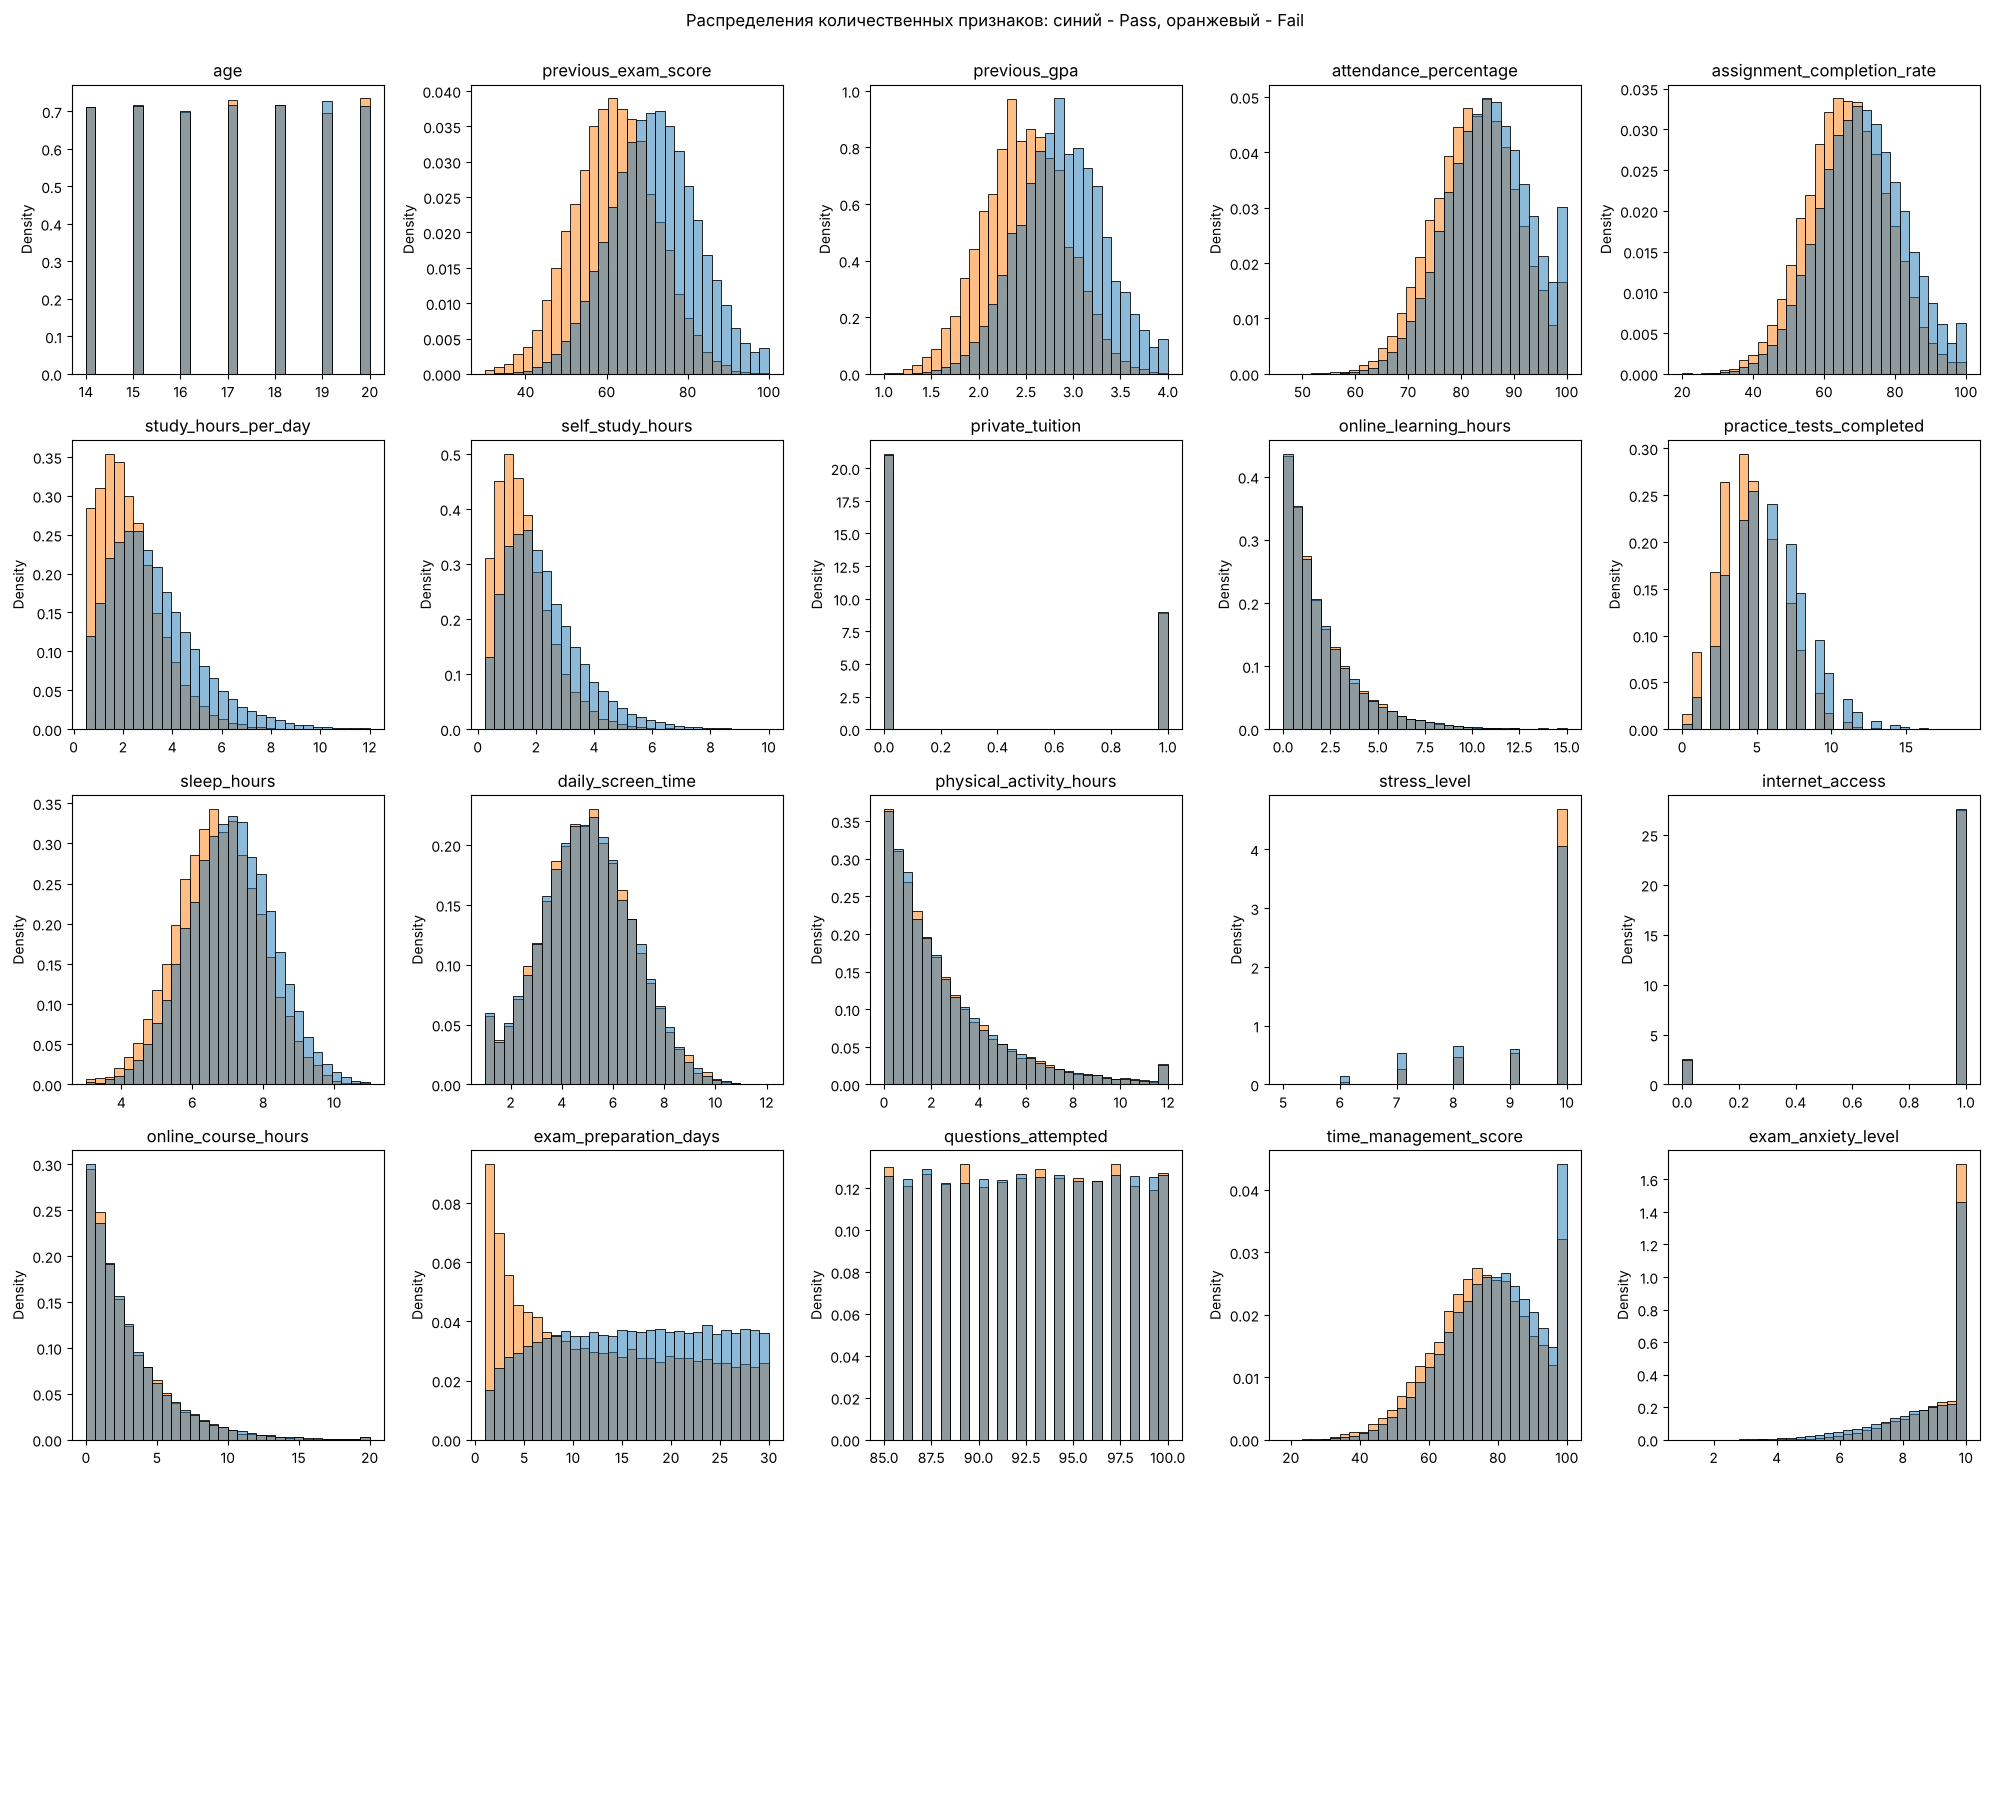

In [13]:
train_df = X_train_raw.assign(fail=y_train.values)
fig, axes = plt.subplots(5, 5, figsize=(20, 18))
for ax, c in zip(axes.flat, numerical_columns):
    sns.histplot(data=train_df, x=c, hue='fail', bins=30, stat='density', common_norm=False, ax=ax, legend=False)
    ax.set_title(c); ax.set_xlabel('')
for ax in axes.flat[len(numerical_columns):]:
    ax.axis('off')
fig.suptitle('Распределения количественных признаков: синий - Pass, оранжевый - Fail', y=1.0)
plt.tight_layout()

In [14]:
fail_rate = []
for c in categorical_columns:
    s = train_df.groupby(c)['fail'].mean()
    fail_rate.append(pd.DataFrame({'признак': c, 'значение': s.index, 'доля Fail': s.values,
                                   'кол-во': train_df[c].value_counts().reindex(s.index).values}))
fail_rate = pd.concat(fail_rate, ignore_index=True)
fail_rate.style.background_gradient(subset=['доля Fail'], cmap='Reds').format({'доля Fail': '{:.3f}'})

,признак,значение,доля Fail,кол-во
0,gender,Female,0.228,36699
1,gender,Male,0.224,36772
2,gender,Other,0.244,1529
3,education_level,High School,0.226,44753
4,education_level,Undergraduate,0.227,30247
5,school_type,Charter,0.231,7455
6,school_type,Private,0.223,26190
7,school_type,Public,0.227,41355
8,family_income,High,0.165,7597
9,family_income,Low,0.284,14982


### Корреляционная матрица

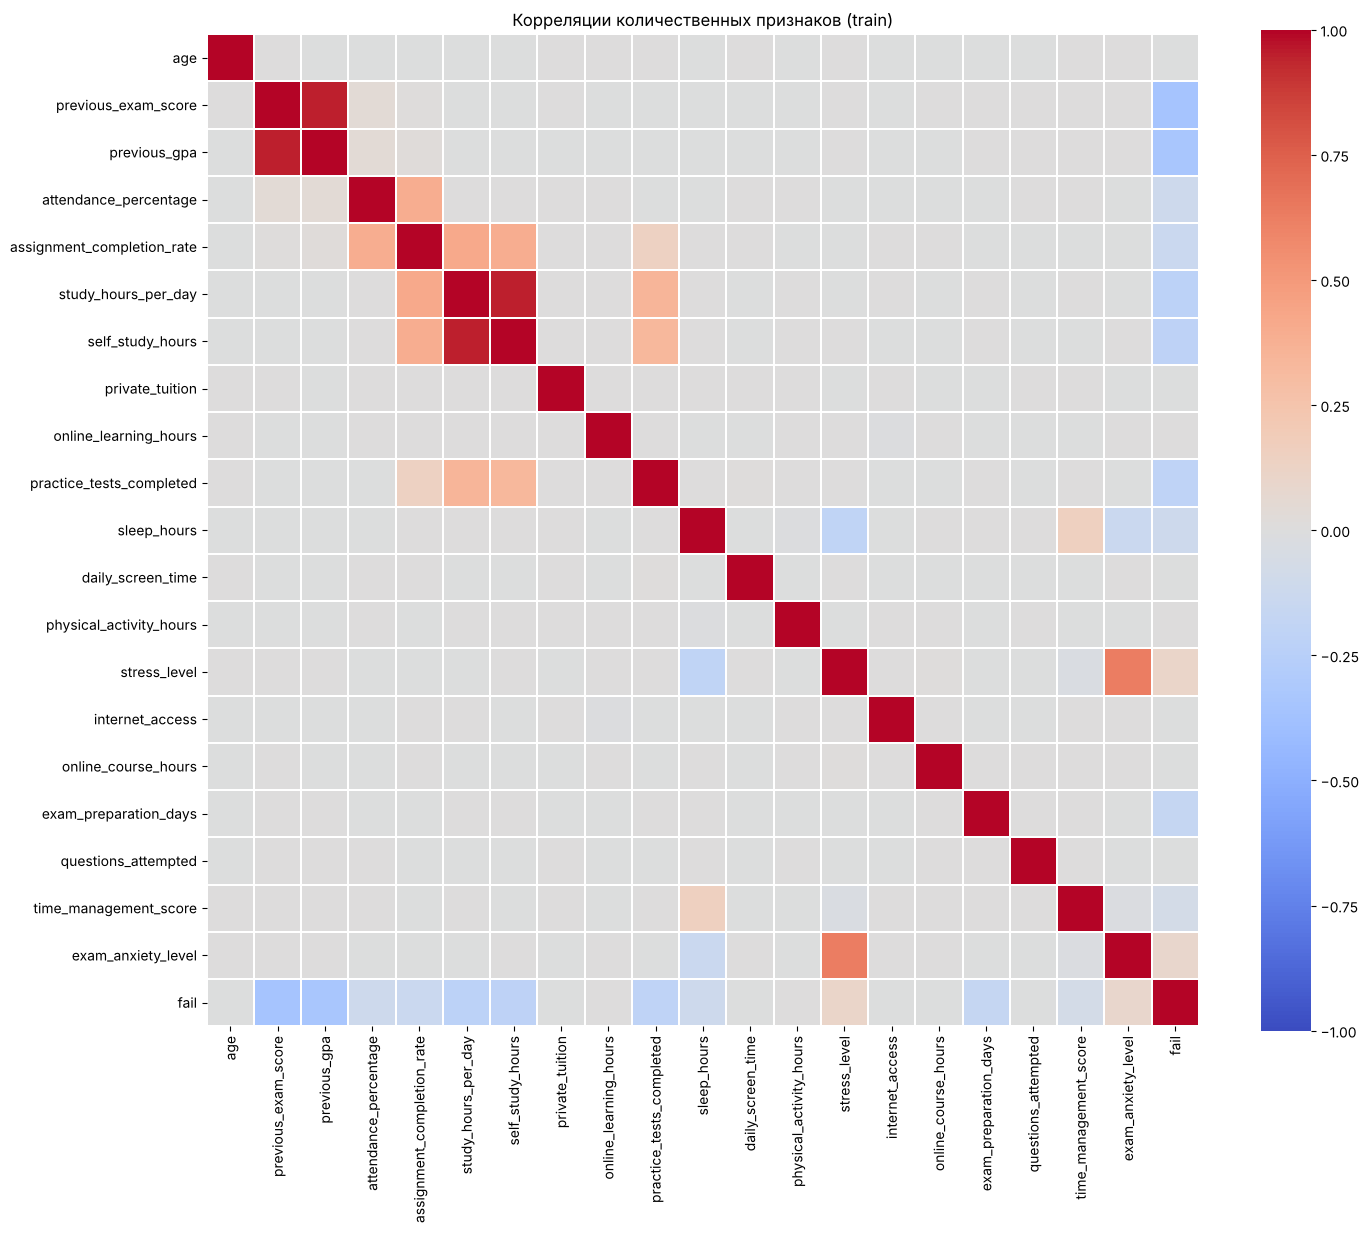

In [15]:
corr = train_df[numerical_columns + ['fail']].corr()
plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, linewidths=.3)
plt.title('Корреляции количественных признаков (train)')
pass

In [16]:
corr['fail'].drop('fail').sort_values(key=abs, ascending=False).head(12)

previous_exam_score          -0.359109
previous_gpa                 -0.339761
study_hours_per_day          -0.225074
self_study_hours             -0.211048
practice_tests_completed     -0.204740
exam_preparation_days        -0.166289
assignment_completion_rate   -0.140027
attendance_percentage        -0.116595
sleep_hours                  -0.115062
stress_level                  0.108742
exam_anxiety_level            0.088822
time_management_score        -0.077531
Name: fail, dtype: float64

In [17]:
c_abs = corr.drop(index='fail', columns='fail').abs()
pairs = (c_abs.where(np.triu(np.ones(c_abs.shape, dtype=bool), k=1)).stack()
         .sort_values(ascending=False))
pairs.head(10)

study_hours_per_day         self_study_hours              0.949643
previous_exam_score         previous_gpa                  0.949033
stress_level                exam_anxiety_level            0.632673
assignment_completion_rate  study_hours_per_day           0.417208
                            self_study_hours              0.395419
attendance_percentage       assignment_completion_rate    0.392175
study_hours_per_day         practice_tests_completed      0.350383
self_study_hours            practice_tests_completed      0.330477
sleep_hours                 stress_level                  0.196989
                            time_management_score         0.152712
dtype: float64

**Интерпретация.**

- С неудачей на экзамене сильнее всего связаны прошлые оценки: `previous_exam_score` ($r = -0.36$) и `previous_gpa` ($-0.34$). Корреляция отрицательная, значит чем выше прошлый балл, тем ниже риск не сдать.
- Дальше идут учебные усилия: часы учёбы ($-0.23$), самостоятельной работы ($-0.21$), число пробных тестов ($-0.20$), дни подготовки ($-0.16$), выполнение заданий ($-0.15$), посещаемость ($-0.13$), сон ($-0.12$). Стресс ($+0.11$) и тревожность ($+0.09$) риск повышают.
- Среди категориальных сильно влияют только два признака: сложность экзамена (доля `Fail`: Easy - 9.7%, Medium - 21.2%, Hard - 38.2%) и доход семьи (Low - 28.2%, High - 16.3%). У всех остальных категориальных признаков (пол, тип школы, метод учёбы, качество сна и т.д.) доля `Fail` во всех группах 22-23%, то есть они почти не несут информации.
- Количественные признаки `age`, `daily_screen_time`, `online_course_hours`, `internet_access`, `private_tuition` и др. коррелируют с целевой на уровне $|r| < 0.01$ - это фактически шум.
- Сильно коррелированные пары: `previous_exam_score` ~ `previous_gpa` ($r = 0.95$), `study_hours_per_day` ~ `self_study_hours` ($0.95$) - почти дубликаты; `stress_level` ~ `exam_anxiety_level` ($0.64$).
- Каждый отдельный признак связан с результатом умеренно ($|r| \le 0.36$), на гистограммах классы сильно перекрываются. Следовательно, безошибочно предсказать результат не получится, наибольшая польза - от сочетания многих признаков.

Итого: из ~38 исходных признаков информативны примерно 14, остальные - шум.

## 4. Выбросы

Ищем значения, которые сильно выпадают из общей картины. Сначала проверим, нет ли невозможных значений (вне описанных в датасете диапазонов), затем посмотрим на ящики с усами и квантили.

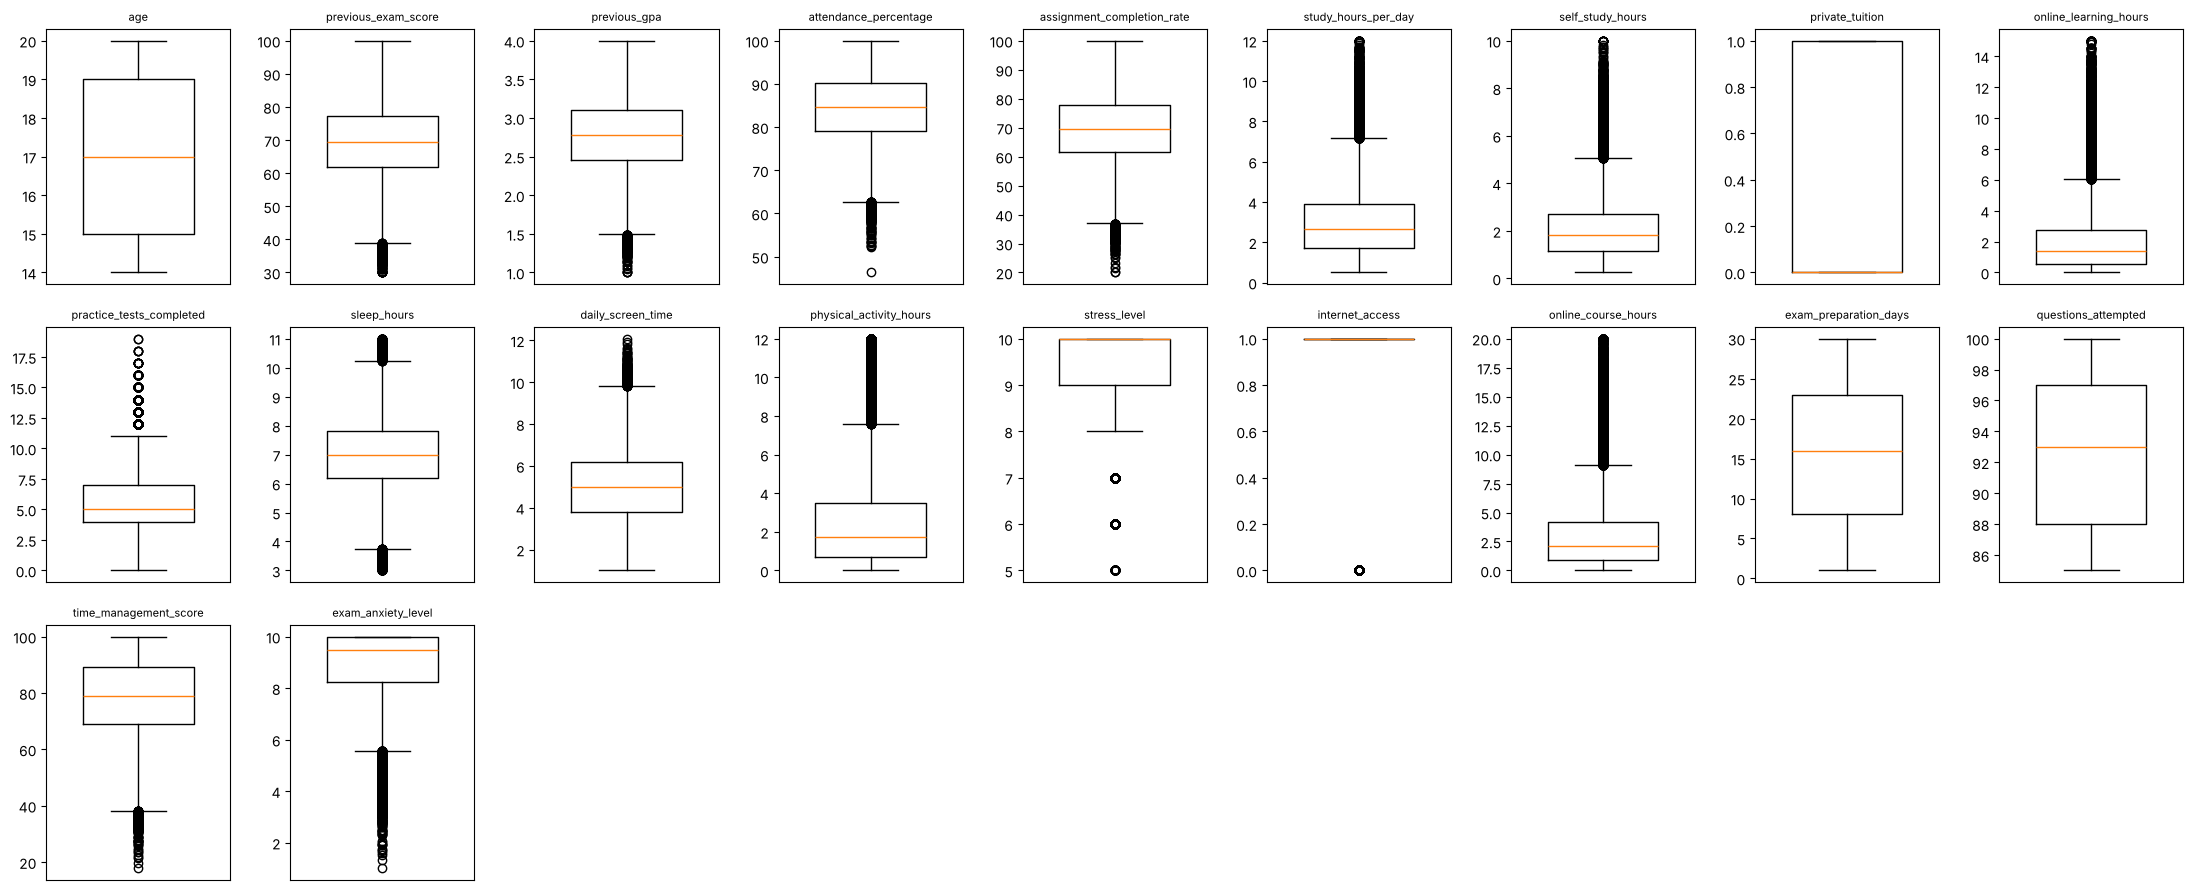

In [18]:
fig, axes = plt.subplots(3, 9, figsize=(22, 9))
for ax, c in zip(axes.flat, numerical_columns):
    ax.boxplot(X_train_raw[c].dropna(), widths=.6)
    ax.set_title(c, fontsize=8); ax.set_xticks([])
for ax in axes.flat[len(numerical_columns):]:
    ax.axis('off')
plt.tight_layout()

In [19]:
q = X_train_raw[numerical_columns].quantile([0, .001, .005, .5, .995, .999, 1]).T
q

,0.000,0.001,0.005,0.500,0.995,0.999,1.000
age,14.00,14.00000,14.00000,17.000,20.00000,20.00000,20.00
previous_exam_score,30.00,34.68999,40.38995,69.535,99.01000,100.00000,100.00
previous_gpa,1.00,1.33000,1.56000,2.780,3.99000,4.00000,4.00
attendance_percentage,46.34,59.50512,63.88140,84.700,100.00000,100.00000,100.00
assignment_completion_rate,20.00,32.59993,38.50985,69.580,100.00000,100.00000,100.00
study_hours_per_day,0.50,0.50000,0.50000,2.670,9.31000,11.11001,12.00
self_study_hours,0.25,0.26000,0.30000,1.840,6.82005,8.42004,10.00
private_tuition,0.00,0.00000,0.00000,0.000,1.00000,1.00000,1.00
online_learning_hours,0.00,0.00000,0.01000,1.370,10.62000,13.71001,15.00
practice_tests_completed,0.00,0.00000,0.00000,5.000,13.00000,15.00000,19.00


In [20]:
# правило 1.5 IQR для каждого признака
Q1 = X_train_raw[numerical_columns].quantile(.25)
Q3 = X_train_raw[numerical_columns].quantile(.75)
IQR = Q3 - Q1
outside = ((X_train_raw[numerical_columns] < Q1 - 1.5*IQR) | (X_train_raw[numerical_columns] > Q3 + 1.5*IQR)).sum()
outside[outside > 0].sort_values(ascending=False)

stress_level                  7539
internet_access               6125
online_learning_hours         3721
physical_activity_hours       3670
online_course_hours           3628
self_study_hours              2269
exam_anxiety_level            2172
study_hours_per_day           2049
practice_tests_completed      1321
sleep_hours                    524
previous_exam_score            254
attendance_percentage          252
daily_screen_time              251
time_management_score          250
assignment_completion_rate     241
previous_gpa                   233
dtype: int64

In [21]:
# невозможных значений нет: проверим это явно по описанию датасета
checks = {'age': (14, 20), 'previous_exam_score': (0, 100), 'previous_gpa': (1, 4),
          'attendance_percentage': (0, 100), 'assignment_completion_rate': (0, 100),
          'sleep_hours': (0, 24), 'study_hours_per_day': (0, 24), 'stress_level': (1, 10),
          'time_management_score': (0, 100), 'exam_anxiety_level': (0, 10)}
for c, (lo, hi) in checks.items():
    bad = ((X_train_raw[c] < lo) | (X_train_raw[c] > hi)).sum()
    print(f'{c:28s} вне [{lo}, {hi}]: {bad}')
# сколько строк train выкинуло бы правило "за пределами квантилей 0.001 и 0.999 хотя бы по одному признаку"
mask = pd.Series(False, index=X_train_raw.index)
for c in numerical_columns:
    lo, hi = X_train_raw[c].quantile([.001, .999])
    mask |= (X_train_raw[c] < lo) | (X_train_raw[c] > hi)
print('Строк за квантилями 0.1%% / 99.9%%: %d (%.1f%%), доля Fail среди них %.3f'
      % (mask.sum(), 100 * mask.mean(), y_train[mask].mean()))

age                          вне [14, 20]: 0
previous_exam_score          вне [0, 100]: 0
previous_gpa                 вне [1, 4]: 0
attendance_percentage        вне [0, 100]: 0
assignment_completion_rate   вне [0, 100]: 0
sleep_hours                  вне [0, 24]: 0
study_hours_per_day          вне [0, 24]: 0
stress_level                 вне [1, 10]: 0
time_management_score        вне [0, 100]: 0
exam_anxiety_level           вне [0, 10]: 0
Строк за квантилями 0.1% / 99.9%: 934 (1.2%), доля Fail среди них 0.281


**Вывод по выбросам.**

- Невозможных значений нет, все признаки лежат в допустимых диапазонах.
- Правило "1.5 IQR" помечает много точек, но это не ошибки, а форма распределений: у `online_learning_hours`, `online_course_hours`, `physical_activity_hours` длинный правый хвост (у немногих студентов очень много часов); `internet_access` и `stress_level` почти константны (у 92% есть интернет, у большинства стресс 10), поэтому любое другое значение формально за усами.
- Строк, выходящих за квантили 0.1% / 99.9% хотя бы по одному признаку, всего 1.2%, причём доля `Fail` среди них заметно выше (0.289 против 0.226). Это крайние случаи (например, очень низкий прошлый балл) и выкинув их, мы бы потеряли именно трудных студентов.

Итог: строки не удаляем. Датасет полусинтетический, значения правдоподобные.

## 5. Пропущенные значения

In [22]:
na = pd.DataFrame({'train': X_train_raw.isna().mean(), 'test': X_test_raw.isna().mean()})
na[na.train > 0].style.format('{:.2%}')

,train,test
parent_education,6.57%,6.39%
previous_gpa,7.73%,7.99%
attendance_percentage,9.83%,9.97%
notes_quality,8.35%,8.58%
sleep_quality,7.00%,6.98%
device_availability,2.89%,3.20%
time_management_score,9.55%,9.80%


In [23]:
# проверяем связь пропусков с целевой переменной
for c in X_train_raw.columns[X_train_raw.isna().any()]:
    m = X_train_raw[c].isna()
    print(f'{c:25s} доля Fail: с пропуском {y_train[m].mean():.3f}, без пропуска {y_train[~m].mean():.3f}')

parent_education          доля Fail: с пропуском 0.227, без пропуска 0.226
previous_gpa              доля Fail: с пропуском 0.223, без пропуска 0.226
attendance_percentage     доля Fail: с пропуском 0.224, без пропуска 0.226
notes_quality             доля Fail: с пропуском 0.224, без пропуска 0.226
sleep_quality             доля Fail: с пропуском 0.225, без пропуска 0.226
device_availability       доля Fail: с пропуском 0.235, без пропуска 0.226
time_management_score     доля Fail: с пропуском 0.220, без пропуска 0.227


Пропусков немного (несколько процентов в 7 столбцах), поэтому удалять строки или столбцы нецелесообразно.

Заполняем пропуски по следующим правилам:

- количественные признаки - медианой,
- категориальные - модой.

Медианы и моды считаем по обучающей выборке и применяем к обеим частям.

In [24]:
X_train = X_train_raw.copy()
X_test  = X_test_raw.copy()
medians = X_train[numerical_columns].median()
modes   = X_train[categorical_columns].mode().iloc[0]
X_train[numerical_columns]   = X_train[numerical_columns].fillna(medians)
X_test[numerical_columns]    = X_test[numerical_columns].fillna(medians)
X_train[categorical_columns] = X_train[categorical_columns].fillna(modes)
X_test[categorical_columns]  = X_test[categorical_columns].fillna(modes)
print('Пропусков осталось:', X_train.isna().sum().sum(), X_test.isna().sum().sum())

Пропусков осталось: 0 0


## 6. Категориальные признаки

В датасете встречаются категориальные признаки трёх видов, каждый обрабатывается по-своему:

- бинарные - 0/1;
- порядковые (значения упорядочены: `Low < Medium < High`, уровни дохода, образование родителей) - целые числа по порядку.
- номинальные (порядка нет: тип школы, место жительства, метод учёбы, пол) - векторизация: признак, принимающий s значений, заменяем на s признаков, принимающих значения 0 или 1 (`pd.get_dummies`).

In [25]:
for c in categorical_columns:
    print(f'{c:25s}', sorted(X_train[c].unique()))

gender                    ['Female', 'Male', 'Other']
education_level           ['High School', 'Undergraduate']
school_type               ['Charter', 'Private', 'Public']
family_income             ['High', 'Low', 'Lower-Middle', 'Middle', 'Upper-Middle']
parent_education          ['Associate', 'Bachelor', 'Doctorate', 'High School', 'Master']
urban_rural               ['Rural', 'Suburban', 'Urban']
class_participation       ['High', 'Low', 'Medium']
study_consistency         ['High', 'Low', 'Medium']
study_environment         ['Moderate', 'Noisy', 'Quiet']
study_method              ['Flashcards', 'Group Study', 'Practice Tests', 'Self-Reading', 'Summarizing']
revision_frequency        ['Daily', 'Rarely', 'Weekly']
notes_quality             ['Average', 'Excellent', 'Poor']
sleep_quality             ['Excellent', 'Fair', 'Good', 'Poor']
break_frequency           ['Frequently', 'Occasionally', 'Rarely']
motivation_level          ['High', 'Low', 'Medium']
device_availability       ['Dedic

In [26]:
# задаём порядок значений порядковых признаков вручную (от "худшего/меньшего" к "лучшему/большему")
ordinal_maps = {
    'family_income':         ['Low', 'Lower-Middle', 'Middle', 'Upper-Middle', 'High'],
    'parent_education':      ['High School', 'Associate', 'Bachelor', 'Master', 'Doctorate'],
    'class_participation':   ['Low', 'Medium', 'High'],
    'study_consistency':     ['Low', 'Medium', 'High'],
    'study_environment':     ['Noisy', 'Moderate', 'Quiet'],
    'revision_frequency':    ['Rarely', 'Weekly', 'Daily'],
    'notes_quality':         ['Poor', 'Average', 'Excellent'],
    'sleep_quality':         ['Poor', 'Fair', 'Good', 'Excellent'],
    'break_frequency':       ['Rarely', 'Occasionally', 'Frequently'],
    'motivation_level':      ['Low', 'Medium', 'High'],
    'educational_app_usage': ['Low', 'Moderate', 'High'],
    'exam_difficulty':       ['Easy', 'Medium', 'Hard'],
}
for c, order in ordinal_maps.items():
    assert set(X_train[c].unique()) == set(order), c

In [27]:
binary_columns  = [c for c in categorical_columns if X_train[c].nunique() == 2 and c not in ordinal_maps]
nominal_columns = [c for c in categorical_columns if c not in ordinal_maps and c not in binary_columns]
print('порядковые:', list(ordinal_maps))
print('бинарные:  ', binary_columns)
print('номинальные:', nominal_columns)

def encode(df):
    df = df.copy()
    for c, order in ordinal_maps.items():
        df[c] = df[c].map({v: i for i, v in enumerate(order)})
    for c in binary_columns:
        first = sorted(X_train[c].unique())[0]
        df[c] = (df[c] != first).astype(int)
    df = pd.get_dummies(df, columns=nominal_columns, drop_first=False, dtype=int)
    return df

X_train_enc = encode(X_train)
X_test_enc  = encode(X_test).reindex(columns=X_train_enc.columns, fill_value=0)
assert X_train_enc.isna().sum().sum() == 0 and X_test_enc.isna().sum().sum() == 0
feature_names = X_train_enc.columns
print(X_train_enc.shape, X_test_enc.shape)
X_train_enc.head()

порядковые: ['family_income', 'parent_education', 'class_participation', 'study_consistency', 'study_environment', 'revision_frequency', 'notes_quality', 'sleep_quality', 'break_frequency', 'motivation_level', 'educational_app_usage', 'exam_difficulty']
бинарные:   ['education_level', 'device_availability']
номинальные: ['gender', 'school_type', 'urban_rural', 'study_method']


(75000, 48) (25000, 48)


,age,education_level,family_income,parent_education,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,time_management_score,exam_anxiety_level,gender_Female,gender_Male,gender_Other,school_type_Charter,school_type_Private,school_type_Public,urban_rural_Rural,urban_rural_Suburban,urban_rural_Urban,study_method_Flashcards,study_method_Group Study,study_method_Practice Tests,study_method_Self-Reading,study_method_Summarizing
16320,20,0,2,1,83.65,2.78,81.76,85.71,0,5.65,3.19,0,2.15,1,2,1,3,1,8.19,2,6.23,0.88,1,10,2,1,0,2,2.40,0,9,94,91.95,10.00,0,1,0,0,0,1,1,0,0,1,0,0,0,0
60442,20,1,2,0,64.66,2.80,93.23,65.69,2,1.82,0.96,1,0.01,0,2,0,6,1,8.23,2,4.54,4.92,1,8,0,1,0,2,1.24,0,15,85,84.97,8.59,0,1,0,0,0,1,0,1,0,1,0,0,0,0
76674,15,1,2,3,55.10,2.22,95.06,91.31,2,6.23,4.77,1,0.17,1,2,1,9,0,5.91,1,8.02,4.97,1,10,0,0,0,0,0.39,1,21,91,75.15,6.95,1,0,0,0,0,1,0,0,1,0,0,0,1,0
98389,17,1,2,0,72.19,3.17,84.70,85.56,2,3.39,2.06,0,1.19,2,0,2,4,1,7.10,2,2.06,1.05,1,10,1,1,1,2,4.62,2,3,91,81.40,10.00,1,0,0,0,1,0,0,1,0,0,0,0,1,0
27732,16,1,1,1,59.41,2.56,84.70,60.50,0,2.07,1.68,0,2.00,1,0,0,7,2,4.76,0,3.32,2.46,1,10,1,1,0,1,2.85,1,23,93,64.92,8.84,0,1,0,0,0,1,0,1,0,1,0,0,0,0


## 7. Нормализация

Нормализация **нужна**: метод ближайших соседей считает евклидовы расстояния, и признак с большим разбросом (например, `previous_exam_score` от 30 до 100) иначе полностью "задавит" признаки вроде `previous_gpa` (от 1 до 4) или бинарные 0/1. То же касается логистической регрессии с регуляризацией, SVM и нейросетей. Деревьям и ансамблям деревьев нормализация не нужна, но и не мешает.

Приводим каждый признак к нулевому среднему и единичному стандартному отклонению. Параметры (`mean`, `std`) считаем по train.

In [28]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train_enc)
X_train_s = scaler.transform(X_train_enc)
X_test_s  = scaler.transform(X_test_enc)
pd.DataFrame(X_train_s, columns=feature_names).describe().T[['mean', 'std']].head(8).round(3)

,mean,std
age,0.0,1.0
education_level,0.0,1.0
family_income,-0.0,1.0
parent_education,0.0,1.0
previous_exam_score,-0.0,1.0
previous_gpa,0.0,1.0
attendance_percentage,0.0,1.0
assignment_completion_rate,-0.0,1.0


## 8. Классификатор ближайших соседей

**Почему kNN.** Это базовый метод из лекции 2: он ничего не предполагает о форме зависимости (в отличие от линейных моделей), у него один понятный гиперпараметр $k$, и он хорошо показывает эффект переобучения/недообучения. Его слабые места - "проклятие размерности" и скорость на больших выборках; посмотрим, как он справится с ~50 признаками и 75 000 объектов. Для сравнения в п. 10 запустим другие методы.

Сначала - kNN с $k = 10$, как на лекции.

In [29]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report, f1_score, roc_auc_score

t = time.time()
knn = KNeighborsClassifier(n_neighbors=10, n_jobs=-1).fit(X_train_s, y_train)
y_test_pred = knn.predict(X_test_s)
print('Ошибка на тесте при k=10: %.4f   (%.0f c)' % (np.mean(y_test != y_test_pred), time.time() - t))

Ошибка на тесте при k=10: 0.2040   (9 c)


## 9. Ошибки на обучающей и тестовой выборках. Матрица рассогласования. Подбор $k$

### 9.1. Ошибки модели с $k = 10$

Матрицу рассогласования и ошибку считаем и на обучающей, и на тестовой выборке. Главное — результат на тесте, но сравнение с обучающей выборкой показывает, насколько модель переобучилась.

In [30]:
y_train_predict = knn.predict(X_train_s)
y_test_predict  = knn.predict(X_test_s)

err_train = np.mean(y_train != y_train_predict)
err_test  = np.mean(y_test  != y_test_predict)
print('k = 10: ошибка на обучающей выборке %.4f, на тестовой %.4f' % (err_train, err_test))

k = 10: ошибка на обучающей выборке 0.1811, на тестовой 0.2040


В матрице рассогласования строки — реальные классы, столбцы — предсказанные. Положительный класс (1) — `Fail`, то есть то, что мы ищем: студентов, которые не сдадут.

| | предсказано `Pass` (0) | предсказано `Fail` (1) |
| --- | --- | --- |
| на самом деле `Pass` (0) | TN — истинно отрицательные | FP — ложные тревоги (ошибки 1-го рода) |
| на самом деле `Fail` (1) | FN — промахи (ошибки 2-го рода) | TP — истинно положительные |

По ней считаются метрики качества:

- ошибка (Error) $= \dfrac{FP + FN}{TN + FP + FN + TP}$, аккуратность (Accuracy) $= 1 - \text{Error}$;
- точность (Precision) $= \dfrac{TP}{TP + FP}$ — доля действительно не сдавших среди тех, кого модель отнесла к `Fail` (делим на сумму в столбце);
- полнота (Recall), она же чувствительность (Sensitivity, TPR) $= \dfrac{TP}{TP + FN}$ — доля найденных среди всех не сдавших (делим на сумму в строке);
- специфичность (Specificity, TNR) $= \dfrac{TN}{TN + FP}$;
- Negative Predictive Value $= \dfrac{TN}{TN + FN}$;
- $F_1 = \dfrac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$ — среднее гармоническое точности и полноты; оно всегда не больше среднего арифметического, то есть даёт более осторожную оценку.

,train,test
Error,0.1811,0.2040
Accuracy,0.8189,0.7960
Precision,0.8509,0.7107
Recall (Sensitivity),0.2414,0.1647
Specificity,0.9876,0.9804
NPV,0.8167,0.8007
F1,0.3761,0.2674


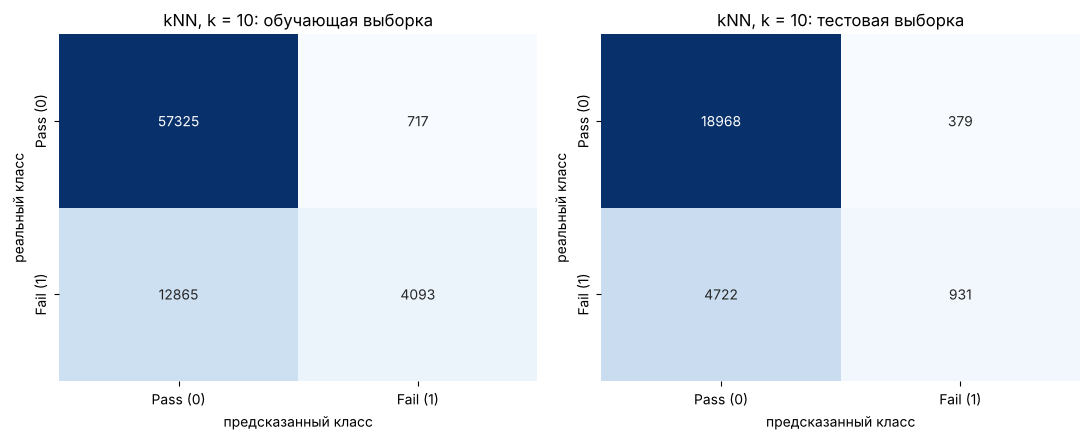

In [31]:
def quality(y_true, y_pred):
    TN, FP, FN, TP = confusion_matrix(y_true, y_pred).ravel()
    return pd.Series({
        'Error':                (FP + FN) / (TN + FP + FN + TP),
        'Accuracy':             (TN + TP) / (TN + FP + FN + TP),
        'Precision':            TP / (TP + FP) if TP + FP > 0 else np.nan,   # nan, если к Fail не отнесён никто
        'Recall (Sensitivity)': TP / (TP + FN),
        'Specificity':          TN / (TN + FP),
        'NPV':                  TN / (TN + FN),
        'F1':                   2 * TP / (2 * TP + FP + FN),
    })

def show_cm(y_true, y_pred, title, ax):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Pass (0)', 'Fail (1)'], yticklabels=['Pass (0)', 'Fail (1)'])
    ax.set_xlabel('предсказанный класс'); ax.set_ylabel('реальный класс'); ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
show_cm(y_train, y_train_predict, 'kNN, k = 10: обучающая выборка', axes[0])
show_cm(y_test,  y_test_predict,  'kNN, k = 10: тестовая выборка',  axes[1])
plt.tight_layout()

pd.DataFrame({'train': quality(y_train, y_train_predict),
              'test':  quality(y_test,  y_test_predict)}).round(4)

Комментарий:

- На обучающей выборке ошибка 0.181, на тестовой 0.204. Разница небольшая, сильного переобучения нет.
- Аккуратность на тесте 0.796 выглядит неплохо, но у классификатора «все сдали» она 0.774, то есть выигрыш всего около 2 процентных пунктов.
- Матрица рассогласования показывает, в чём дело: модель почти всем говорит `Pass`. Полнота (чувствительность) на тесте всего 0.165: из всех не сдавших найден лишь каждый шестой. Точность 0.711: если модель сказала `Fail`, она права в 71% случаев. Специфичность 0.980 высокая только потому, что студентов `Pass` много и почти всех их модель относит к `Pass`.
- Для нашей задачи (найти студентов в зоне риска) такой классификатор плохой, хотя по одной аккуратности этого не видно. Поэтому при несбалансированных классах смотрим на всю матрицу рассогласования и на точность с полнотой.

### 9.2. Подбор числа соседей $k$ методом перекрестного контроля

Тестовая выборка ни в коем случае не должна участвовать в обучении и в подборе гиперпараметров: она изображает новые данные, которых модель ещё не видела. Если подбирать $k$ по тесту, тест фактически станет обучающей выборкой, и оценка ошибки получится заниженной.

Поэтому $k$ подбираем методом перекрестного контроля по $M = 5$ блокам (5-fold cross-validation) только на обучающей выборке:

1. обучающая выборка случайно разбивается на 5 примерно равных частей;
2. для каждого $k$ модель 5 раз обучается на четырёх частях и проверяется на оставшейся (проверочной, validation);
3. 5 ошибок усредняются — это оценка ошибки модели с данным $k$;
4. выбирается $k$ с наименьшей средней ошибкой;
5. модель с найденным $k$ обучается на всей обучающей выборке и один раз проверяется на тестовой.

`GridSearchCV` делает шаги 1–4 автоматически.

In [32]:
from sklearn.model_selection import GridSearchCV

k_arr = np.array([1, 3, 5, 7, 10, 15, 20, 30, 40, 50, 75, 100])
t = time.time()
grid = GridSearchCV(KNeighborsClassifier(), {'n_neighbors': k_arr}, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_s, y_train)
print('%.0f c' % (time.time() - t))

best_k = grid.best_params_['n_neighbors']
print('Лучшее k =', best_k, ' средняя ошибка на кросс-валидации = %.4f' % (1 - grid.best_score_))

268 c
Лучшее k = 15  средняя ошибка на кросс-валидации = 0.2001


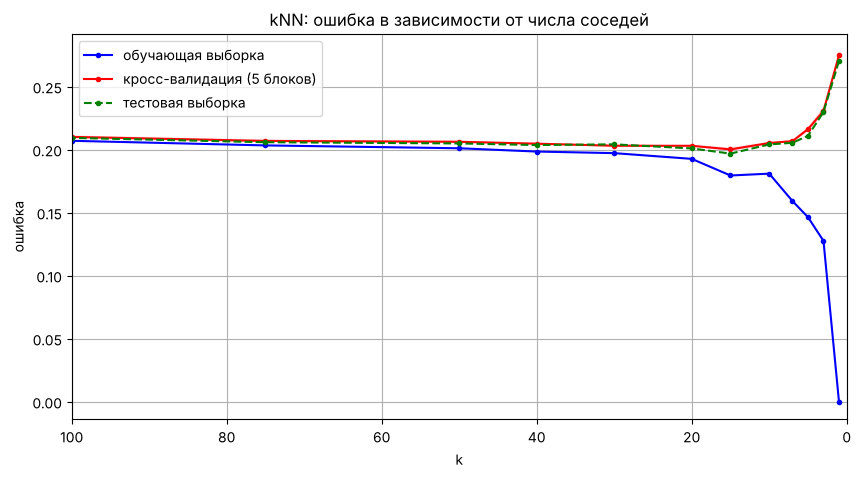

In [33]:
# Для сравнения посчитаем ошибки на обучающей и тестовой выборках при тех же k
# (ошибку на обучающей выборке для скорости считаем по случайным 15 000 объектам)
idx_sub = np.random.RandomState(RANDOM_STATE).choice(len(y_train), 15000, replace=False)
err_train_arr, err_test_arr = [], []
for k in k_arr:
    m = KNeighborsClassifier(n_neighbors=k, n_jobs=-1).fit(X_train_s, y_train)
    err_train_arr.append(np.mean(y_train.iloc[idx_sub] != m.predict(X_train_s[idx_sub])))
    err_test_arr.append(np.mean(y_test != m.predict(X_test_s)))

err_cv_arr = 1 - grid.cv_results_['mean_test_score']
std_arr = grid.cv_results_['std_test_score']

plt.figure(figsize=(10, 5))
plt.plot(k_arr, err_train_arr, 'b.-', label='обучающая выборка')
plt.plot(k_arr, err_cv_arr, 'r.-', label='кросс-валидация (5 блоков)')
plt.fill_between(k_arr, err_cv_arr - std_arr, err_cv_arr + std_arr, alpha=0.15, facecolor='red')
plt.plot(k_arr, err_test_arr, 'g.--', label='тестовая выборка')
plt.xlim([max(k_arr), 0])      # вправо — модель сложнее
plt.grid()
plt.xlabel('k'); plt.ylabel('ошибка'); plt.legend()
plt.title('kNN: ошибка в зависимости от числа соседей')
pass

In [34]:
pd.DataFrame({'k': k_arr, 'train': err_train_arr, 'CV': err_cv_arr, 'test': err_test_arr}).set_index('k').round(4)

,train,CV,test
k,,,
1,0.0000,0.2746,0.2702
3,0.1275,0.2306,0.2297
5,0.1463,0.2162,0.2109
7,0.1591,0.2066,0.2054
10,0.1809,0.2052,0.2040
15,0.1794,0.2001,0.1968
20,0.1926,0.2030,0.2009
30,0.1971,0.2030,0.2041
40,0.1984,0.2046,0.2036


### 9.3. Итоговая модель с оптимальным $k$

k = 15: ошибка на обучающей выборке 0.1782, на тестовой 0.1968


,train,test
Error,0.1782,0.1968
Accuracy,0.8218,0.8032
Precision,0.8281,0.7374
Recall (Sensitivity),0.2675,0.2017
Specificity,0.9838,0.9790
NPV,0.8213,0.8076
F1,0.4044,0.3167


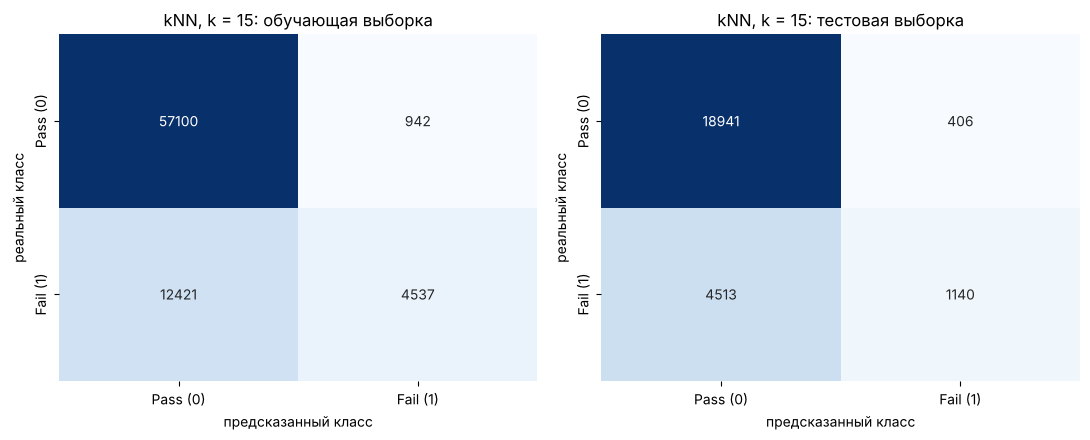

In [35]:
knn = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1).fit(X_train_s, y_train)
y_train_predict = knn.predict(X_train_s)
y_test_predict  = knn.predict(X_test_s)

err_train = np.mean(y_train != y_train_predict)
err_test  = np.mean(y_test  != y_test_predict)
print('k = %d: ошибка на обучающей выборке %.4f, на тестовой %.4f' % (best_k, err_train, err_test))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
show_cm(y_train, y_train_predict, f'kNN, k = {best_k}: обучающая выборка', axes[0])
show_cm(y_test,  y_test_predict,  f'kNN, k = {best_k}: тестовая выборка',  axes[1])
plt.tight_layout()

pd.DataFrame({'train': quality(y_train, y_train_predict),
              'test':  quality(y_test,  y_test_predict)}).round(4)

Комментарий:

- При $k = 1$ ошибка на обучающей выборке равна 0 (каждый объект — сам себе ближайший сосед), а на тестовой 0.270 — переобучение. С ростом $k$ ошибка на обучающей выборке растёт, а на кросс-валидации и на тесте сначала падает, потом снова растёт: при больших $k$ ответ усредняется по множеству уже не очень похожих студентов и модель становится слишком сглаженной — недообучение. Нужна «золотая середина».
- Ось $k$ развёрнута: движение слева направо соответствует росту сложности модели (меньше соседей — более «нервная» граница между классами).
- Минимум ошибки на кросс-валидации — при $k = 15$ (0.200). Кривые кросс-валидации и теста почти совпадают, значит кросс-валидация хорошо оценивает ошибку на новых данных, и выбор $k$ без использования теста оправдан.
- Итоговая модель с $k = 15$: ошибка на обучающей выборке 0.178, на тестовой 0.197. Полнота выросла с 0.165 до 0.202, $F_1$ — с 0.267 до 0.317, но модель по-прежнему находит только каждого пятого не сдавшего.
- Причина в том, что многие признаки не связаны с результатом (в п. 3 видно, что информативна примерно треть). В евклидово расстояние все признаки входят с одинаковым весом, и соседи подбираются в основном по шумовым признакам. К тому же из-за дисбаланса среди 15 соседей почти всегда большинство `Pass`. С этим разбираемся в п. 11 и 12.

### 9.4. ROC- и PR-кривые

kNN выдаёт не только класс, но и число от 0 до 1 — долю соседей класса `Fail` (`predict_proba`). Это дискриминантная функция $g(x)$: чем она больше, тем модель увереннее, что студент не сдаст. По умолчанию порог $0.5$: $f(x) = I(g(x) \ge 0.5)$. Но порог можно менять, и тогда меняется соотношение между ошибками 1-го и 2-го рода.

- ROC-кривая — зависимость TPR (чувствительности) от FPR $= 1 - $ специфичность при изменении порога. Идеальный классификатор проходит через точку $(0, 1)$, случайный — по диагонали.
- AUC — площадь под ROC-кривой, равна доле правильно упорядоченных пар объектов (`Fail` получил score больше, чем `Pass`). Для случайного классификатора $\approx 0.5$, для идеального $1$.
- PR-кривая — зависимость точности (Precision) от полноты (Recall) при изменении порога. В отличие от ROC-кривой она немонотонная.

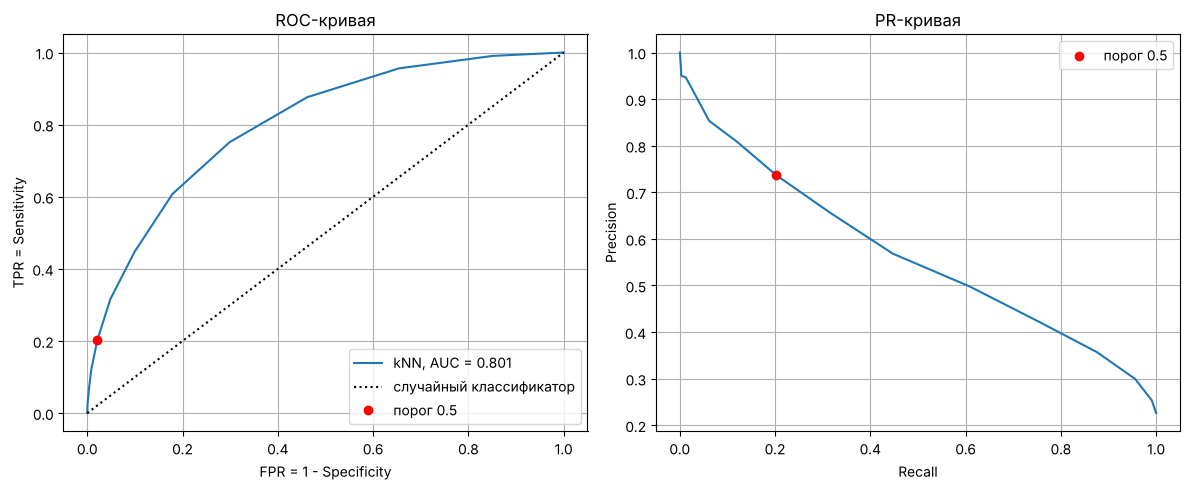

In [36]:
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score

scores = knn.predict_proba(X_test_s)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, scores)
precision, recall, thresholds_pr = precision_recall_curve(y_test, scores)
auc_knn = roc_auc_score(y_test, scores)

q = quality(y_test, y_test_predict)   # точка с порогом 0.5
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, label=f'kNN, AUC = {auc_knn:.3f}')
axes[0].plot([0, 1], [0, 1], 'k:', label='случайный классификатор')
axes[0].plot(1 - q['Specificity'], q['Recall (Sensitivity)'], 'ro', label='порог 0.5')
axes[0].set_xlabel('FPR = 1 - Specificity'); axes[0].set_ylabel('TPR = Sensitivity'); axes[0].set_title('ROC-кривая')
axes[1].plot(recall, precision)
axes[1].plot(q['Recall (Sensitivity)'], q['Precision'], 'ro', label='порог 0.5')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].set_title('PR-кривая')
for ax in axes: ax.grid(); ax.legend()
plt.tight_layout()

Комментарий: AUC = 0.801 — модель заметно лучше случайной (0.5): студентов `Fail` она в целом оценивает выше, чем `Pass`, но до идеала далеко. Красная точка — порог 0.5: высокая специфичность и низкая чувствительность. Если сдвигать порог вниз, точка поедет по кривой вверх и вправо: найдём больше не сдавших ценой большего числа ложных тревог (это делаем в п. 11).

## 10. Другие классификаторы

Запустим другие методы на тех же данных и соберём результаты в таблицы, как в примере с оценкой стоимости квартиры: в `err_table` — ошибки на обучающей и тестовой выборках, в `metrics_table` — метрики на тесте.

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

err_table = pd.DataFrame(columns=['train', 'test'])
metrics_table = pd.DataFrame(columns=['Precision', 'Recall', 'Specificity', 'F1', 'ROC AUC'])
test_scores = {}   # значения дискриминантной функции на тесте — для ROC-кривых
models = {}

def evaluate(name, model, X_tr=X_train_s, y_tr=y_train, fit=True):
    t = time.time()
    models[name] = model
    if fit:
        model.fit(X_tr, y_tr)
    y_train_predict = model.predict(X_tr)
    y_test_predict  = model.predict(X_test_s)
    s = model.predict_proba(X_test_s)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_test_s)
    test_scores[name] = s
    q = quality(y_test, y_test_predict)
    err_table.loc[name] = [np.mean(y_tr != y_train_predict), q['Error']]
    metrics_table.loc[name] = [q['Precision'], q['Recall (Sensitivity)'], q['Specificity'], q['F1'], roc_auc_score(y_test, s)]
    print(f'{name:35s} {time.time() - t:6.1f} c')

evaluate(f'kNN (k = {best_k})', knn, fit=False)
evaluate('Логистическая регрессия', LogisticRegression(max_iter=1000))
evaluate('LDA', LinearDiscriminantAnalysis())
evaluate('Наивный байесовский', GaussianNB())
evaluate('Дерево решений (глубина 8)', DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE))
evaluate('Случайный лес (200 деревьев)', RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE))
evaluate('Градиентный бустинг', HistGradientBoostingClassifier(random_state=RANDOM_STATE))
evaluate('Нейронная сеть (20, 10)', MLPClassifier(hidden_layer_sizes=(20, 10), max_iter=500, random_state=RANDOM_STATE))

# SVM обучается за время ~N^2, поэтому берём случайные 10 000 объектов обучающей выборки
idx = np.random.RandomState(RANDOM_STATE).choice(len(y_train), 10000, replace=False)
evaluate('SVM, RBF-ядро (10 000 объектов)', SVC(), X_tr=X_train_s[idx], y_tr=y_train.iloc[idx])

kNN (k = 15)                          45.0 c


Логистическая регрессия                0.7 c


LDA                                    1.4 c
Наивный байесовский                    0.2 c


Дерево решений (глубина 8)             0.9 c


Случайный лес (200 деревьев)          39.9 c


Градиентный бустинг                   19.4 c


Нейронная сеть (20, 10)               33.0 c


SVM, RBF-ядро (10 000 объектов)       17.0 c


In [38]:
err_table.astype(float).sort_values('test').round(4)

,train,test
Градиентный бустинг,0.1311,0.1478
"Нейронная сеть (20, 10)",0.1356,0.1522
Логистическая регрессия,0.1505,0.1527
LDA,0.1512,0.1528
Случайный лес (200 деревьев),0.0000,0.1546
"SVM, RBF-ядро (10 000 объектов)",0.0946,0.1590
Дерево решений (глубина 8),0.1556,0.1709
Наивный байесовский,0.1915,0.1937
kNN (k = 15),0.1782,0.1968


In [39]:
metrics_table.astype(float).sort_values('ROC AUC', ascending=False).round(4)

,Precision,Recall,Specificity,F1,ROC AUC
Градиентный бустинг,0.7194,0.5675,0.9353,0.6345,0.8983
"Нейронная сеть (20, 10)",0.7045,0.5627,0.9310,0.6257,0.8940
Логистическая регрессия,0.7138,0.5418,0.9365,0.6160,0.8925
LDA,0.7324,0.5112,0.9454,0.6021,0.8916
Случайный лес (200 деревьев),0.7627,0.4589,0.9583,0.5730,0.8851
"SVM, RBF-ядро (10 000 объектов)",0.7165,0.4914,0.9432,0.5830,0.8782
Дерево решений (глубина 8),0.6874,0.4481,0.9405,0.5425,0.8490
Наивный байесовский,0.5608,0.6605,0.8489,0.6066,0.8483
kNN (k = 15),0.7374,0.2017,0.9790,0.3167,0.8014


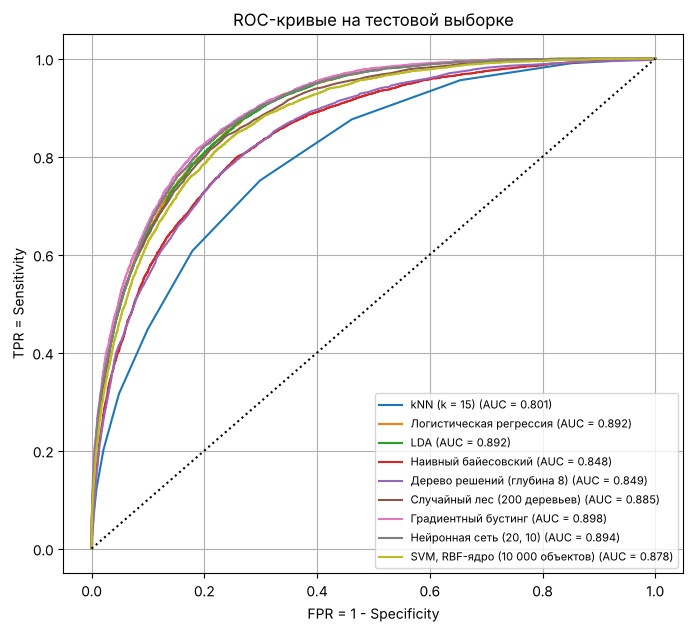

In [40]:
plt.figure(figsize=(8, 7))
for name, s in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, s):.3f})')
plt.plot([0, 1], [0, 1], 'k:')
plt.xlabel('FPR = 1 - Specificity'); plt.ylabel('TPR = Sensitivity')
plt.title('ROC-кривые на тестовой выборке'); plt.legend(fontsize=8); plt.grid()
pass

Случайный лес и градиентный бустинг позволяют оценить «важность» признаков: чем значение больше, тем признак важнее.

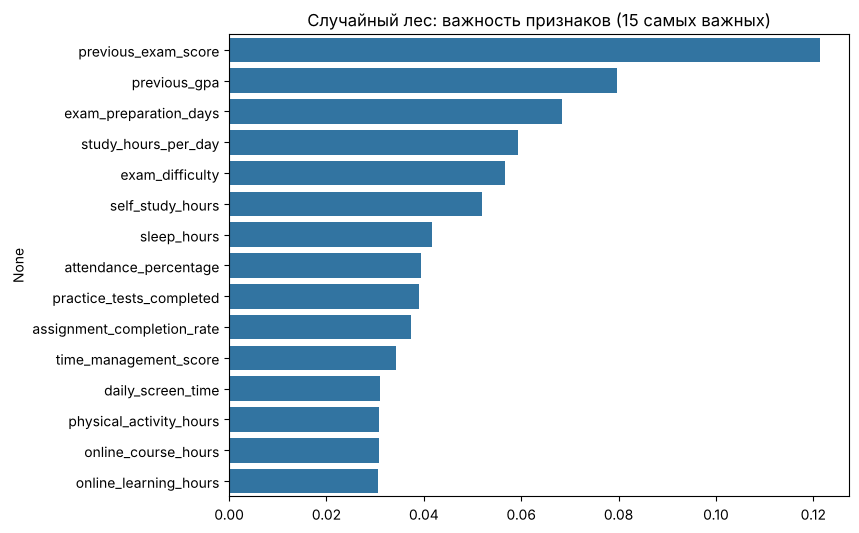

In [41]:
rf = models['Случайный лес (200 деревьев)']
importances = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)
plt.figure(figsize=(8, 6))
sns.barplot(y=importances.index[:15], x=importances.values[:15], orient='h')
plt.title('Случайный лес: важность признаков (15 самых важных)')
pass

Комментарий:

- Лучший результат у градиентного бустинга: ошибка на тесте 0.148, ROC AUC 0.898. Близко к нему нейронная сеть (0.152), логистическая регрессия и LDA (0.153).
- Линейные модели почти не уступают сложным: зависимость в этих данных близка к линейной. Логистическая регрессия — хорошая простая базовая модель, и у неё ошибки на обучающей и тестовой выборках почти совпадают (0.151 и 0.153).
- Случайный лес на обучающей выборке не ошибается совсем (0.000), а на тестовой даёт 0.155. Большая разница между train и test означает переобучение, но для случайного леса это скорее исключение: усреднение многих деревьев всё равно даёт хорошую ошибку на тесте. Одиночное дерево хуже (0.171). SVM тоже заметно переобучается (0.095 и 0.159).
- Наивный байесовский классификатор по ошибке слабый (0.194), но у него самая высокая полнота (0.661): он чаще других говорит `Fail`. Его предположение о независимости признаков здесь нарушено — например, `previous_exam_score` и `previous_gpa` почти дублируют друг друга.
- kNN — худший (ошибка 0.197, полнота 0.202, AUC 0.801).
- Важность признаков в случайном лесе согласуется с корреляционным анализом из п. 3: на первых местах прошлые оценки (`previous_exam_score`, `previous_gpa`), часы учёбы, сложность экзамена и дни подготовки.
- Важность в случайном лесе нужно читать осторожно: признаки `daily_screen_time`, `physical_activity_hours`, `online_course_hours` попали в первую 15, хотя с результатом почти не коррелируют. Лес часто использует непрерывные признаки с множеством значений для мелких разбиений, поэтому их «важность» немного завышена.

## 11. Несбалансированность классов

Классы несбалансированы: `Fail` — 22.6%, `Pass` — 77.4%. При дисбалансе одного числа (ошибки или аккуратности) мало. Например, классификатор, который всем говорит `Pass`, имеет аккуратность 0.774, но не находит ни одного не сдавшего.

Что важнее: точность или полнота? Это зависит от задачи и от того, что назвать положительным классом. В медицинской диагностике важнее полнота (чувствительность): промах — пропущенная болезнь — опаснее ложной тревоги. В детектировании спама важнее точность: ложная тревога — потерянное важное письмо. Наша задача похожа на медицинскую диагностику: мы ищем студентов в зоне риска, и промах (не заметили, что студент не сдаст) хуже ложной тревоги (лишний раз обратили внимание на сильного студента). Поэтому смотрим прежде всего на полноту, но следим и за точностью через $F_1$.

Попробуем три способа улучшить полноту:

1. Сдвиг порога дискриминантной функции. Модель уже обучена, мы только меняем порог, при котором студент относится к `Fail`. Порог выбираем по обучающей выборке (через кросс-валидацию), а не по тесту.
2. Веса классов (`class_weight='balanced'`): ошибка на объекте редкого класса штрафуется сильнее.
3. Undersampling для kNN: случайно убираем часть студентов `Pass` из обучающей выборки, чтобы классов стало поровну.

In [42]:
from sklearn.model_selection import cross_val_predict

const_pred = np.zeros_like(y_test)
imb_table = pd.DataFrame({'Константа «все сдали»': quality(y_test, const_pred)}).T
imb_table

,Error,Accuracy,Precision,Recall (Sensitivity),Specificity,NPV,F1
Константа «все сдали»,0.22612,0.77388,NaN,0.0,1.0,0.77388,0.0


### 11.1. Сдвиг порога

Где проводить порог, зависит от требований заказчика. Допустим, требование такое: найти не меньше 80% не сдавших (Recall ≥ 0.8), а ложных тревог при этом — как можно меньше. Тогда на кривой выбираем самый большой порог, при котором полнота ещё не меньше 0.8. Второй вариант — порог, при котором максимальна $F_1$.

Берём логистическую регрессию и градиентный бустинг. Значения дискриминантной функции на обучающей выборке получаем через `cross_val_predict` (каждый объект предсказан моделью, которая его не видела), по ним выбираем порог, а проверяем на тесте.

In [43]:
def choose_thresholds(model, name):
    s_cv = cross_val_predict(model, X_train_s, y_train, cv=5, method='predict_proba')[:, 1]
    precision, recall, thr = precision_recall_curve(y_train, s_cv)
    precision, recall = precision[:-1], recall[:-1]
    t_recall = thr[recall >= 0.8].max()                       # самый большой порог с Recall >= 0.8
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    t_f1 = thr[np.argmax(f1)]                                   # порог с максимальной F1
    model.fit(X_train_s, y_train)
    s_test = model.predict_proba(X_test_s)[:, 1]
    for t, label in [(0.5, 'порог 0.5'), (t_f1, f'порог {t_f1:.2f} (max F1)'), (t_recall, f'порог {t_recall:.2f} (Recall ≥ 0.8)')]:
        imb_table.loc[f'{name}, {label}'] = quality(y_test, (s_test >= t).astype(int))
    return s_test, t_f1, t_recall

s_lr, t_f1_lr, t_rec_lr = choose_thresholds(LogisticRegression(max_iter=1000), 'Лог. регрессия')
s_gb, t_f1_gb, t_rec_gb = choose_thresholds(HistGradientBoostingClassifier(random_state=RANDOM_STATE), 'Град. бустинг')

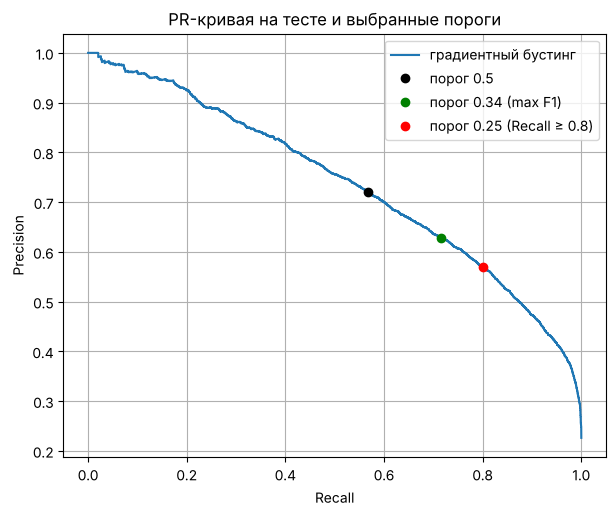

In [44]:
precision, recall, thr = precision_recall_curve(y_test, s_gb)
plt.figure(figsize=(7, 5.5))
plt.plot(recall, precision, label='градиентный бустинг')
for t, c, lab in [(0.5, 'k', 'порог 0.5'), (t_f1_gb, 'g', f'порог {t_f1_gb:.2f} (max F1)'), (t_rec_gb, 'r', f'порог {t_rec_gb:.2f} (Recall ≥ 0.8)')]:
    p = (s_gb >= t).astype(int)
    q = quality(y_test, p)
    plt.plot(q['Recall (Sensitivity)'], q['Precision'], 'o', color=c, label=lab)
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('PR-кривая на тесте и выбранные пороги')
plt.grid(); plt.legend()
pass

### 11.2. Веса классов и undersampling

In [45]:
for name, model in [('Лог. регрессия, class_weight=balanced', LogisticRegression(max_iter=1000, class_weight='balanced')),
                    ('Случайный лес, class_weight=balanced', RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE))]:
    model.fit(X_train_s, y_train)
    imb_table.loc[name] = quality(y_test, model.predict(X_test_s))

# undersampling для kNN: оставляем всех Fail и столько же случайных Pass
rng = np.random.RandomState(RANDOM_STATE)
y_tr = y_train.to_numpy()
i_fail = np.where(y_tr == 1)[0]
i_pass = rng.choice(np.where(y_tr == 0)[0], len(i_fail), replace=False)
i_us = np.concatenate([i_fail, i_pass])
knn_us = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1).fit(X_train_s[i_us], y_tr[i_us])
imb_table.loc[f'kNN (k = {best_k})'] = quality(y_test, knn.predict(X_test_s))
imb_table.loc[f'kNN (k = {best_k}), undersampling'] = quality(y_test, knn_us.predict(X_test_s))

imb_table.round(4)

,Error,Accuracy,Precision,Recall (Sensitivity),Specificity,NPV,F1
Константа «все сдали»,0.2261,0.7739,NaN,0.0000,1.0000,0.7739,0.0000
"Лог. регрессия, порог 0.5",0.1527,0.8473,0.7138,0.5418,0.9365,0.8749,0.6160
"Лог. регрессия, порог 0.31 (max F1)",0.1726,0.8274,0.5955,0.7380,0.8535,0.9177,0.6591
"Лог. регрессия, порог 0.24 (Recall ≥ 0.8)",0.1921,0.8079,0.5522,0.7957,0.8114,0.9315,0.6519
"Град. бустинг, порог 0.5",0.1478,0.8522,0.7194,0.5675,0.9353,0.8810,0.6345
"Град. бустинг, порог 0.34 (max F1)",0.1600,0.8400,0.6283,0.7163,0.8762,0.9136,0.6694
"Град. бустинг, порог 0.25 (Recall ≥ 0.8)",0.1822,0.8178,0.5689,0.8015,0.8225,0.9341,0.6654
"Лог. регрессия, class_weight=balanced",0.2008,0.7992,0.5369,0.8137,0.7949,0.9359,0.6469
"Случайный лес, class_weight=balanced",0.1784,0.8216,0.5825,0.7451,0.8440,0.9189,0.6538
kNN (k = 15),0.1968,0.8032,0.7374,0.2017,0.9790,0.8076,0.3167


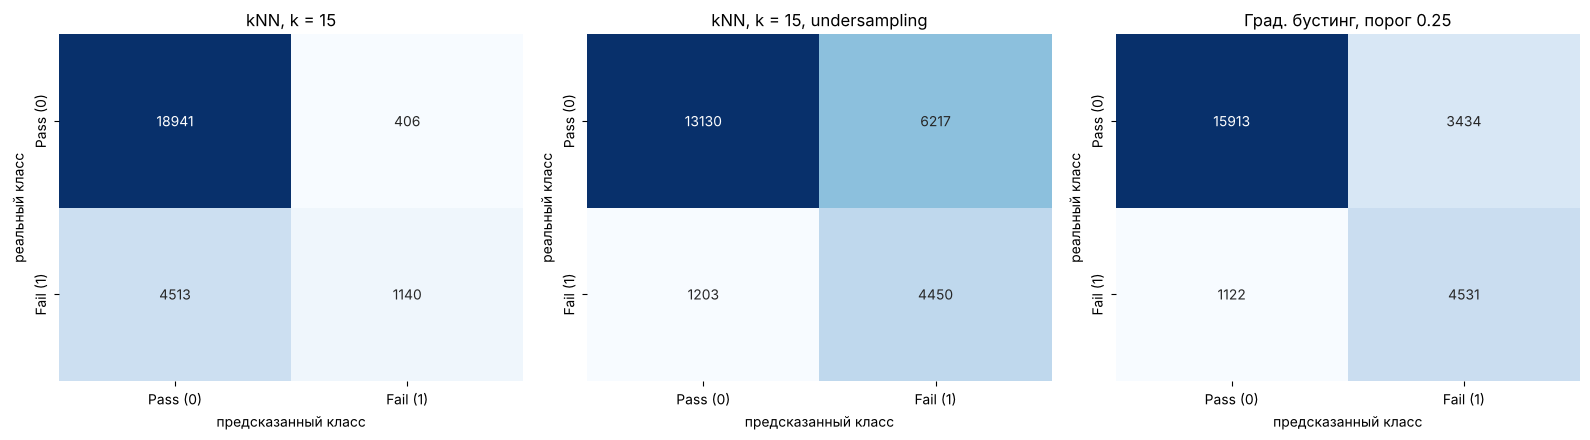

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
show_cm(y_test, knn.predict(X_test_s), f'kNN, k = {best_k}', axes[0])
show_cm(y_test, knn_us.predict(X_test_s), f'kNN, k = {best_k}, undersampling', axes[1])
show_cm(y_test, (s_gb >= t_rec_gb).astype(int), f'Град. бустинг, порог {t_rec_gb:.2f}', axes[2])
plt.tight_layout()

Комментарий:

- Сдвиг порога работает. У градиентного бустинга при пороге 0.25 полнота 0.80 вместо 0.57 при пороге 0.5: находим 4 из 5 не сдавших. Плата — больше ложных тревог: точность падает с 0.72 до 0.57, ошибка растёт с 0.148 до 0.182.
- Порог, выбранный по максимуму $F_1$ (0.34 у бустинга), — компромисс: полнота 0.72, точность 0.63, $F_1$ = 0.67 — лучшее значение $F_1$ в таблице.
- Пороги выбирались только по обучающей выборке, а на тесте полнота получилась 0.80 у обеих моделей, то есть требование «найти не меньше 80% не сдавших» выполняется и на новых данных.
- Веса классов дают похожий эффект: у логистической регрессии полнота 0.81, у случайного леса 0.75.
- Undersampling поднимает полноту kNN с 0.20 до 0.79, но точность падает до 0.42, а ошибка растёт до 0.297.
- Ошибка (и аккуратность) при этом у всех становится хуже, чем при пороге 0.5. При дисбалансе классов «минимальная ошибка» и «максимальная полнота» — разные цели, и какой порог выбрать, зависит от того, во что обходится промах и во что — ложная тревога.

## 12. Исключение коррелированных признаков

Зачем. Сильно коррелированные признаки несут почти одну и ту же информацию. Для kNN это значит, что одно и то же свойство входит в расстояние дважды, то есть получает двойной вес. Для линейных моделей (логистическая регрессия, LDA) это мультиколлинеарность: коэффициенты становятся неустойчивыми и плохо интерпретируются. Кроме того, чем меньше признаков, тем проще модель и быстрее обучение.

Из каждой пары признаков с $|r| > 0.8$ (по обучающей выборке) удаляем тот, который слабее связан с целевой переменной.

In [47]:
THR = 0.8
num_enc = [c for c in feature_names if c in numerical_columns or c in ordinal_maps]
C = X_train_enc[num_enc].corr().abs()
r_target = X_train_enc[num_enc].corrwith(y_train).abs()
to_drop = set()
for a in C.columns:
    for b in C.columns:
        if a < b and C.loc[a, b] > THR and a not in to_drop and b not in to_drop:
            drop = a if r_target[a] < r_target[b] else b
            to_drop.add(drop)
            print(f'{a} ~ {b}: r = {C.loc[a, b]:.3f}  -> удаляем {drop}')
to_drop = sorted(to_drop)
keep = [i for i, c in enumerate(feature_names) if c not in to_drop]
X_train_r, X_test_r = X_train_s[:, keep], X_test_s[:, keep]
print('Признаков было %d, стало %d' % (X_train_s.shape[1], X_train_r.shape[1]))

previous_exam_score ~ previous_gpa: r = 0.913  -> удаляем previous_gpa
self_study_hours ~ study_hours_per_day: r = 0.950  -> удаляем self_study_hours
Признаков было 48, стало 46


In [48]:
corr_table = pd.DataFrame(columns=['train', 'test', 'Recall', 'F1'])
for name, model, Xtr, Xte in [
        (f'kNN (k = {best_k}), все признаки',            knn, X_train_s, X_test_s),
        (f'kNN (k = {best_k}), без коррелированных',     KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1), X_train_r, X_test_r),
        ('Лог. регрессия, все признаки',                LogisticRegression(max_iter=1000), X_train_s, X_test_s),
        ('Лог. регрессия, без коррелированных',         LogisticRegression(max_iter=1000), X_train_r, X_test_r)]:
    model.fit(Xtr, y_train)
    q = quality(y_test, model.predict(Xte))
    corr_table.loc[name] = [np.mean(y_train != model.predict(Xtr)), q['Error'], q['Recall (Sensitivity)'], q['F1']]
corr_table.astype(float).round(4)

,train,test,Recall,F1
"kNN (k = 15), все признаки",0.1782,0.1968,0.2017,0.3167
"kNN (k = 15), без коррелированных",0.1873,0.2051,0.1493,0.2477
"Лог. регрессия, все признаки",0.1505,0.1527,0.5418,0.6160
"Лог. регрессия, без коррелированных",0.1504,0.1527,0.5431,0.6167


Комментарий:

- Удалены `previous_gpa` (почти дубль `previous_exam_score`, $r = 0.91$) и `self_study_hours` (дубль `study_hours_per_day`, $r = 0.95$).
- Логистическая регрессия не изменилась (ошибка на тесте 0.153 в обоих случаях), зато модель стала проще и её коэффициенты легче интерпретировать.
- kNN стал хуже: ошибка 0.197 → 0.205, полнота 0.202 → 0.149. Дубли были среди немногих информативных признаков: пока оба признака были в расстоянии, важное свойство имело двойной вес по сравнению с шумовыми. Удалив один из них, мы ослабили полезный сигнал. Значит, главная проблема kNN здесь не корреляции, а шумовые признаки.

### 12.1. Оставляем только информативные признаки

Раз kNN мешают не дубли, а шумовые признаки, оставим только признаки, хоть как-то связанные с целевой переменной. Упорядочим признаки по модулю корреляции с `fail` (по обучающей выборке) и для разного числа признаков $m$ подберём $k$ кросс-валидацией (здесь по 3 блокам, чтобы быстрее).

previous_exam_score           0.359
previous_gpa                  0.327
exam_difficulty               0.243
study_hours_per_day           0.225
self_study_hours              0.211
practice_tests_completed      0.205
exam_preparation_days         0.166
assignment_completion_rate    0.140
sleep_hours                   0.115
attendance_percentage         0.111
stress_level                  0.109
exam_anxiety_level            0.089
family_income                 0.086
time_management_score         0.074
study_method_Self-Reading     0.007
dtype: float64


624 c


,лучшее k,ошибка CV
m,,
4,100,0.1820
6,100,0.1759
8,60,0.1667
10,60,0.1616
12,60,0.1590
14,60,0.1608
16,60,0.1647
20,40,0.1728
30,20,0.1894


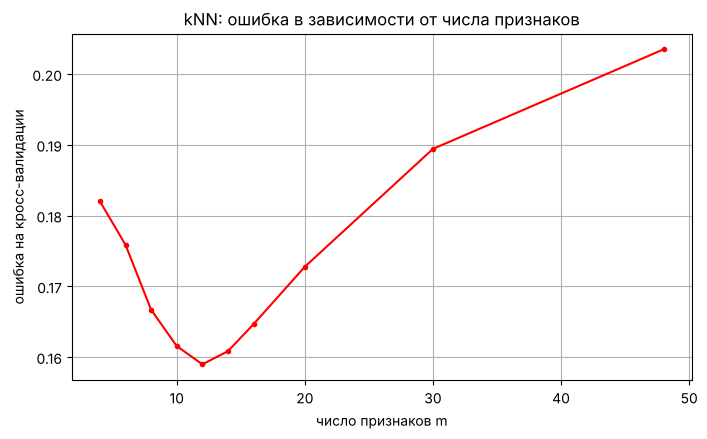

In [49]:
r_all = pd.Series(np.abs([np.corrcoef(X_train_s[:, j], y_train)[0, 1] for j in range(X_train_s.shape[1])]),
                  index=feature_names).sort_values(ascending=False)
print(r_all.head(15).round(3))

m_arr = [4, 6, 8, 10, 12, 14, 16, 20, 30, len(feature_names)]
k_small = [20, 40, 60, 80, 100]
sel_results = []
t = time.time()
for m in m_arr:
    cols = [feature_names.get_loc(c) for c in r_all.index[:m]]
    g = GridSearchCV(KNeighborsClassifier(), {'n_neighbors': k_small}, cv=3, scoring='accuracy', n_jobs=-1)
    g.fit(X_train_s[:, cols], y_train)
    sel_results.append((m, g.best_params_['n_neighbors'], 1 - g.best_score_))
print('%.0f c' % (time.time() - t))
sel_results = pd.DataFrame(sel_results, columns=['m', 'лучшее k', 'ошибка CV']).set_index('m')

plt.figure(figsize=(8, 4.5))
plt.plot(sel_results.index, sel_results['ошибка CV'], 'r.-')
plt.xlabel('число признаков m'); plt.ylabel('ошибка на кросс-валидации'); plt.grid()
plt.title('kNN: ошибка в зависимости от числа признаков')
sel_results.round(4)

Отобранные признаки: ['previous_exam_score', 'previous_gpa', 'exam_difficulty', 'study_hours_per_day', 'self_study_hours', 'practice_tests_completed', 'exam_preparation_days', 'assignment_completion_rate', 'sleep_hours', 'attendance_percentage', 'stress_level', 'exam_anxiety_level']


kNN, 12 признаков, k = 60: ошибка на обучающей выборке 0.1533, на тестовой 0.1602


,все признаки,12 признаков
Error,0.1968,0.1602
Accuracy,0.8032,0.8398
Precision,0.7374,0.7489
Recall (Sensitivity),0.2017,0.4389
Specificity,0.9790,0.9570
NPV,0.8076,0.8537
F1,0.3167,0.5534


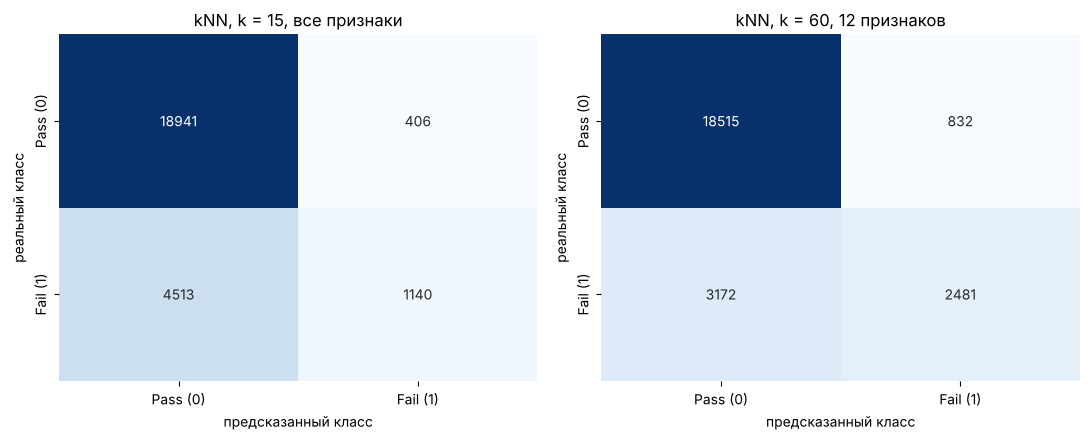

In [50]:
best_m = sel_results['ошибка CV'].idxmin()
best_k_sel = int(sel_results.loc[best_m, 'лучшее k'])
sel_cols = [feature_names.get_loc(c) for c in r_all.index[:best_m]]
print('Отобранные признаки:', list(r_all.index[:best_m]))

knn_sel = KNeighborsClassifier(n_neighbors=best_k_sel, n_jobs=-1).fit(X_train_s[:, sel_cols], y_train)
y_train_predict = knn_sel.predict(X_train_s[:, sel_cols])
y_test_predict  = knn_sel.predict(X_test_s[:, sel_cols])
print(f'kNN, {best_m} признаков, k = {best_k_sel}: ошибка на обучающей выборке %.4f, на тестовой %.4f'
      % (np.mean(y_train != y_train_predict), np.mean(y_test != y_test_predict)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
show_cm(y_test, knn.predict(X_test_s), f'kNN, k = {best_k}, все признаки', axes[0])
show_cm(y_test, y_test_predict, f'kNN, k = {best_k_sel}, {best_m} признаков', axes[1])
plt.tight_layout()

s_sel = knn_sel.predict_proba(X_test_s[:, sel_cols])[:, 1]
pd.DataFrame({'все признаки': quality(y_test, knn.predict(X_test_s)),
              f'{best_m} признаков': quality(y_test, y_test_predict)}).round(4)

Комментарий:

- Ошибка на кросс-валидации в зависимости от числа признаков — «чаша»: при малом $m$ теряем полезную информацию, при большом расстояние тонет в шумовых признаках. Минимум — при $m = 12$ и $k = 60$ (0.159).
- Отобраны ровно те признаки, которые в п. 3 оказались связаны с результатом: прошлые оценки, сложность экзамена, учебные часы, пробные тесты, дни подготовки, выполнение заданий, сон, посещаемость, стресс и тревожность.
- На тесте ошибка kNN упала с 0.197 до 0.160, полнота выросла с 0.20 до 0.44, $F_1$ — с 0.32 до 0.55. Разница между обучающей и тестовой выборками маленькая (0.153 и 0.160). kNN поднялся почти до уровня логистической регрессии.
- Вывод: для метода ближайших соседей отбор признаков оказался важнее, чем подбор $k$. Удаление столбцов — один из основных способов борьбы с переобучением, но удалять нужно в первую очередь неинформативные признаки, а не обязательно коррелированные.

## 13. Общие выводы

1. Решалась задача бинарной классификации: по 38 признакам студента предсказать, сдаст ли он экзамен. Положительный класс — `Fail` (22.6% студентов), потому что цель — найти студентов в зоне риска.
2. Данные разделены на обучающую (75%) и тестовую (25%) выборки. Тестовая выборка использовалась только для финальной оценки; гиперпараметры подбирались кросс-валидацией по 5 блокам на обучающей выборке, после чего модель обучалась на всей обучающей выборке.
3. Метод $k$ ближайших соседей: оптимальное $k = 15$, ошибка на обучающей выборке 0.178, на тестовой 0.197. С уменьшением $k$ ошибка на обучающей выборке падает до нуля, а на тестовой сначала падает, потом растёт (переобучение при малых $k$, недообучение при больших).
4. Одной ошибки (или аккуратности) при несбалансированных классах недостаточно. У kNN аккуратность 0.80 — почти как у константы «все сдали» (0.77), а полнота всего 0.20: находится только каждый пятый не сдавший. Это видно только по матрице рассогласования и метрикам точность / полнота / $F_1$, ROC AUC = 0.80.
5. Причина слабости kNN — много неинформативных признаков. Если оставить 12 признаков, связанных с результатом, ошибка kNN падает до 0.160, полнота растёт до 0.44. Удаление коррелированных признаков kNN не помогло, а логистическую регрессию не изменило.
6. Лучшие методы: градиентный бустинг (ошибка 0.148, ROC AUC 0.898), нейронная сеть (0.152), логистическая регрессия и LDA (0.153). Ошибка около 15% у всех сильных методов — вероятно, это близко к неустранимой ошибке для этих данных. Случайный лес и SVM заметно переобучаются (ошибка на обучающей выборке намного меньше, чем на тестовой).
7. Для нашей задачи полнота важнее точности: пропустить студента в зоне риска хуже, чем ложная тревога. Сдвиг порога дискриминантной функции, выбранный по обучающей выборке, позволяет найти 80% не сдавших (градиентный бустинг, порог 0.25: полнота 0.80, точность 0.57). Порог с максимальной $F_1$ (0.34) даёт компромисс: полнота 0.72, точность 0.63, $F_1$ = 0.67. Где именно проводить порог, зависит от того, во что обходится каждая ошибка.